# Project 5 — Industrial Predictive Maintenance & Failure Prevention
### Full Pipeline: Data Prep → Machine Learning → Deep Learning → Model Comparison

This notebook merges the three pieces of the project into one coherent pipeline:

| Part | Section | Roadmap area covered |
|---|---|---|
| 1 | Python / Math / Data Prep | EDA, cleaning, feature engineering |
| 2 | Shared modeling setup | Leakage-safe feature/target definition, train/test split |
| 3 | Machine Learning track | LR → Decision Tree → Random Forest → Gradient Boosting, tuning, SHAP |
| 4 | Deep Learning track (I) | MLP classifier |
| 5 | Deep Learning track (II) | Autoencoder — unsupervised anomaly detection |
| 6 | Final comparison | Classical ML vs Deep Learning, on the same test set |

**Before running:** put `ai4i2020.csv` in the same folder as this notebook.

**Requirements:** `pandas numpy matplotlib seaborn scikit-learn torch shap joblib`
(if `shap` or `torch` aren't installed, run `pip install shap torch` first — the SHAP
section is wrapped so the rest of the notebook still runs without it.)

---

**A note on what changed while merging:** while combining the original ML and DL
notebooks, I found and fixed one important bug — the deep learning section was
accidentally using the five failure-mode flags (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) as
*input features*. Since `Machine failure` is essentially the union of those flags, that's
textbook target leakage — the model was being handed the answer. It's fixed below by
building **one shared feature list** that both the ML and DL sections use, so this can't
happen again and the two tracks are guaranteed to be compared fairly on the same data.

---
# Part 1 — Python / Math / Data Prep

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Load the data

Wrapping this in a small function rather than a bare `pd.read_csv` — this is the
kind of thing that ends up moving into `src/data/loading.py` later.

In [2]:
def load_raw_data(path="ai4i2020.csv"):
    """Load the raw AI4I 2020 predictive maintenance dataset."""
    df = pd.read_csv(path)
    return df


df = load_raw_data()
print("Shape:", df.shape)
df.head()


Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
# checking for missing values

df.isnull().sum()


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [5]:
# Any duplicate rows or duplicate machine IDs?
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Product IDs:", df["Product ID"].duplicated().sum())


Duplicate rows: 0
Duplicate Product IDs: 0


In [6]:
# Basic descriptive statistics for the numeric sensor columns
numeric_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


## Understanding the target

The dataset gives us two things to predict:
- `Machine failure` — the overall binary label (1 = failed)
- Five specific failure-mode flags: `TWF`, `HDF`, `PWF`, `OSF`, `RNF`

For the main classification track we'll mostly use `Machine failure` — but as the note
at the top of this notebook explains, the failure-mode flags must **never** be used as
model inputs, only as something we check the target against.

Overall failure rate: 3.39%
Failures: 339 out of 10000 records


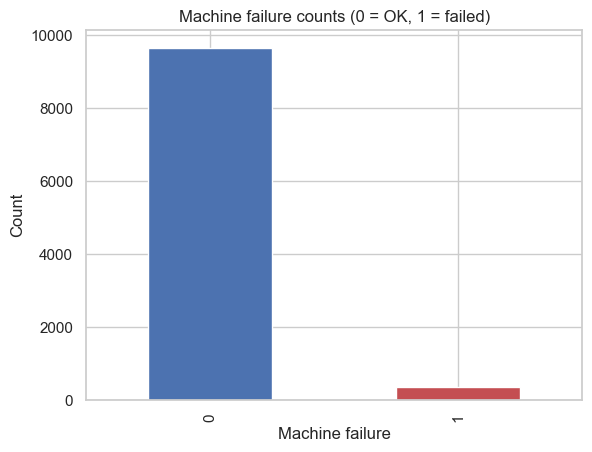

In [7]:
fail_rate = df["Machine failure"].mean()
print(f"Overall failure rate: {fail_rate:.2%}")
print(f"Failures: {df['Machine failure'].sum()} out of {len(df)} records")

df["Machine failure"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"])
plt.title("Machine failure counts (0 = OK, 1 = failed)")
plt.xlabel("Machine failure")
plt.ylabel("Count")
plt.show()


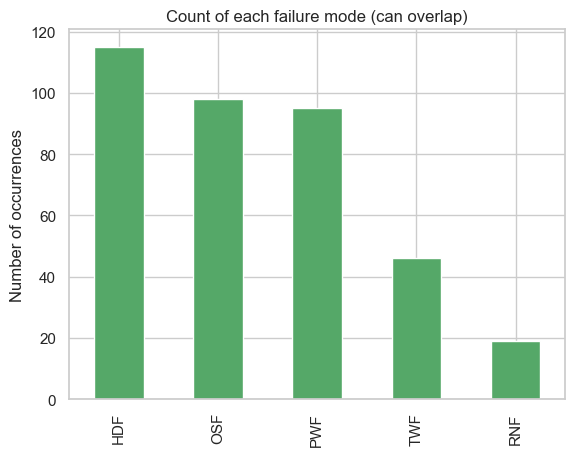

In [8]:
# This is a strongly imbalanced problem (failures are rare, important to remember)
# for the ML section later: accuracy alone would be a useless metric here.

failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df[failure_modes].sum().sort_values(ascending=False).plot(kind="bar", color="#55A868")
plt.title("Count of each failure mode (can overlap)")
plt.ylabel("Number of occurrences")
plt.show()


In [9]:
# Sanity check: does Machine failure = 1 whenever any failure mode is triggered?
any_mode_triggered = df[failure_modes].any(axis=1)
mismatch = (any_mode_triggered != df["Machine failure"].astype(bool)).sum()
print(f"Rows where the failure modes and 'Machine failure' disagree: {mismatch}")


Rows where the failure modes and 'Machine failure' disagree: 27


## Distribution of the sensor variables

Quick univariate look at each numeric feature — helps spot skew, outliers, or
anything that looks off before we start engineering features.

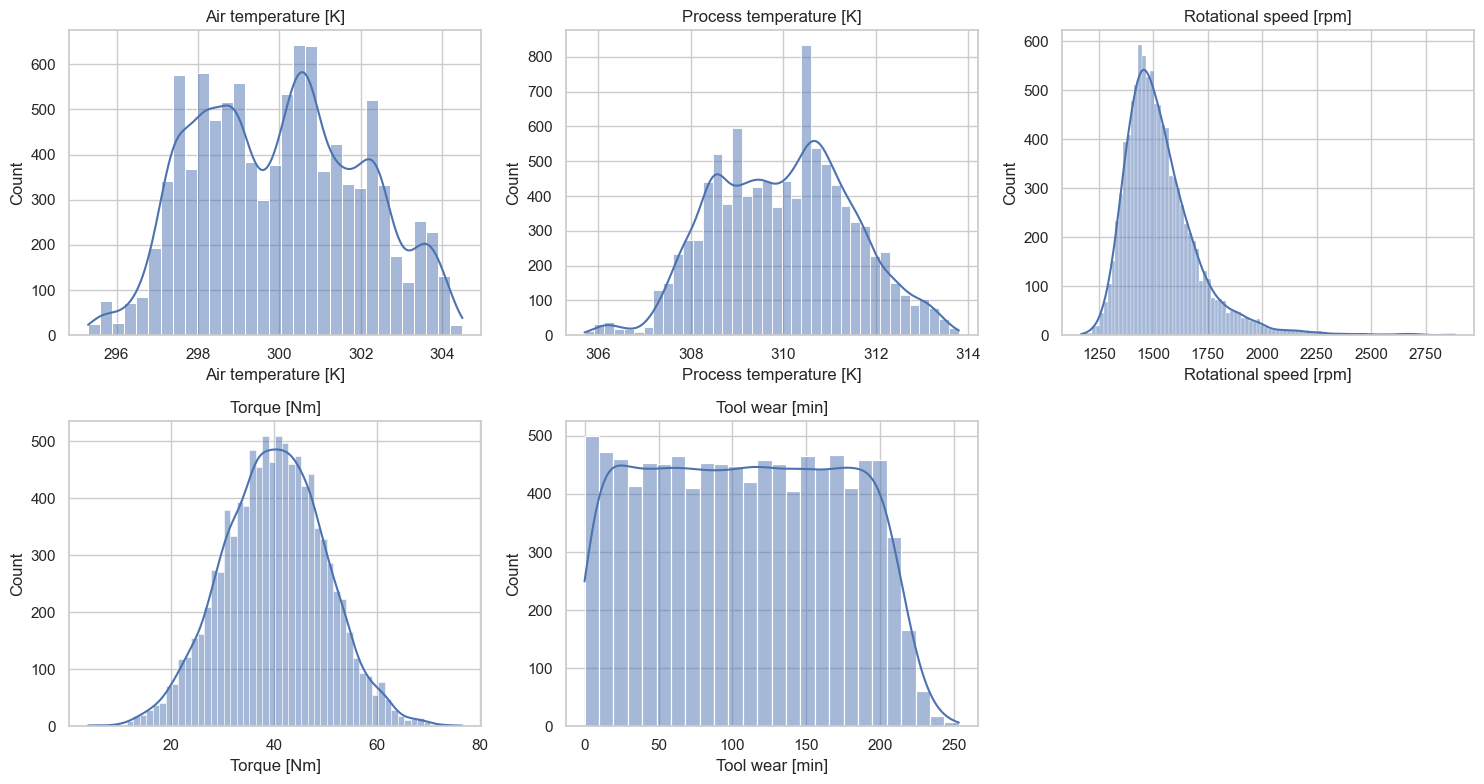

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)

axes[-1].axis("off")
plt.tight_layout()
plt.show()


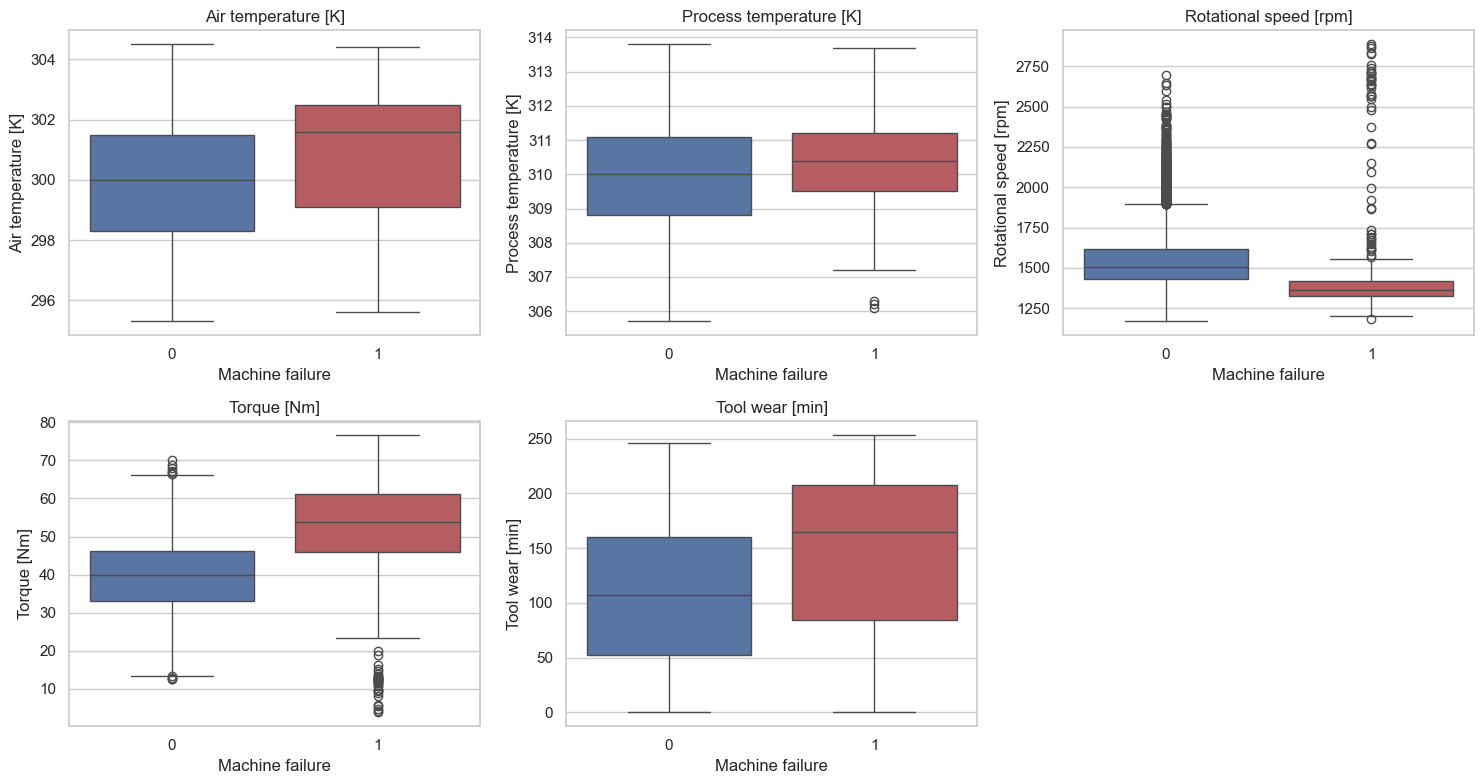

In [11]:
# Same variables, but split by failure status — do failed machines look different?
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, hue="Machine failure",
                palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
    ax.set_title(col)

axes[-1].axis("off")
plt.tight_layout()
plt.show()


## Categorical variable: product `Type`

Each product is quality grade L (low), M (medium), or H (high). Worth checking whether
failure rate differs by grade — it's the kind of thing that becomes a useful feature.

In [12]:
type_counts = df["Type"].value_counts()
print(type_counts)

df.groupby("Type")["Machine failure"].mean().sort_values(ascending=False)


Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


Type
L    0.039167
M    0.027694
H    0.020937
Name: Machine failure, dtype: float64

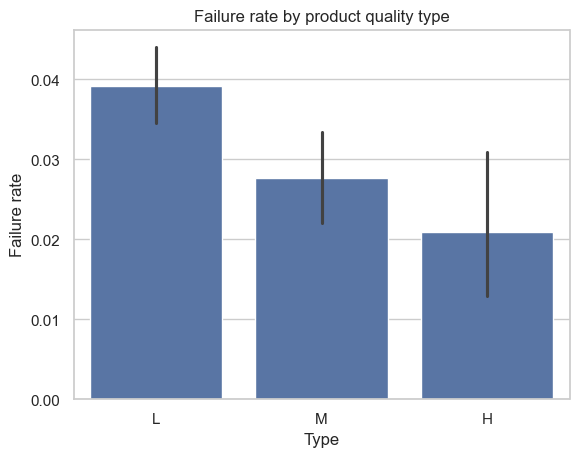

In [13]:
sns.barplot(data=df, x="Type", y="Machine failure", order=["L", "M", "H"], color="#4C72B0")
plt.title("Failure rate by product quality type")
plt.ylabel("Failure rate")
plt.show()


## Correlation between numeric features

A simple correlation heatmap to see which sensor readings move together, and which
ones actually correlate with failure.

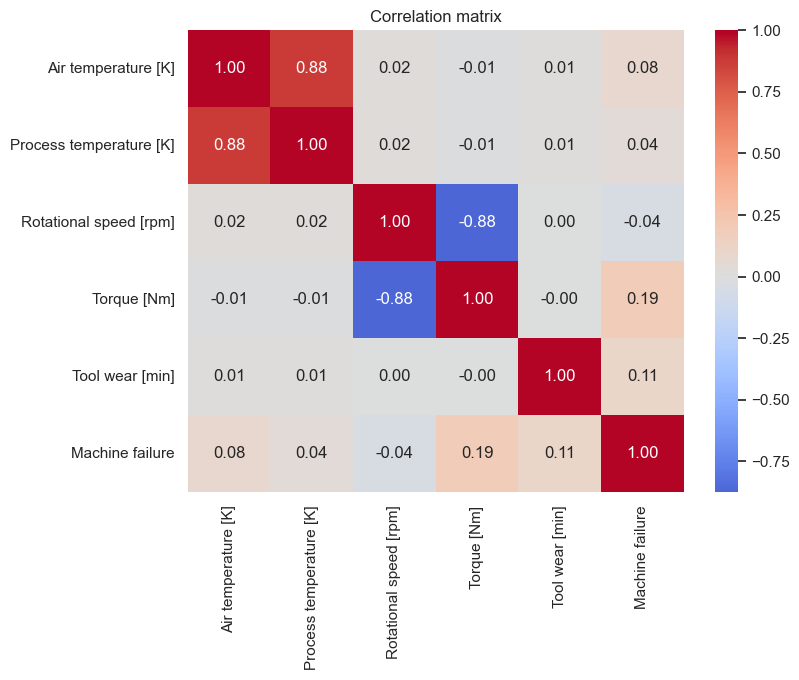

In [14]:
corr_cols = numeric_cols + ["Machine failure"]
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()


## Feature engineering

A few domain-informed features that should help the models later, based on how these
machines actually work:

- **Temperature difference** (`Process temperature - Air temperature`): a machine working
  much hotter than ambient air is a classic early-warning sign.
- **Mechanical power** (`Torque x Rotational speed`, converted to watts): combines two raw
  sensors into the physical quantity that actually drives wear and heat failures.
- **Tool wear x Torque**: an interaction term; a worn tool under high torque is riskier
  than either alone.
- **Numeric encoding of `Type`**: turning L/M/H into an ordinal 0/1/2, since it does reflect
  an ordered quality grade.

Wrapping this in one function keeps it reusable and testable.

In [15]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    """Add engineered features to the AI4I dataset. Returns a new dataframe (no in-place mutation)."""
    data = data.copy()

    data["Temp_diff [K]"] = data["Process temperature [K]"] - data["Air temperature [K]"]

    angular_speed = data["Rotational speed [rpm]"] * (2 * np.pi / 60)
    data["Power [W]"] = data["Torque [Nm]"] * angular_speed

    data["Wear_Torque_interaction"] = data["Tool wear [min]"] * data["Torque [Nm]"]

    type_order = {"L": 0, "M": 1, "H": 2}
    data["Type_encoded"] = data["Type"].map(type_order)

    return data


df_features = add_features(df)
df_features[["Temp_diff [K]", "Power [W]", "Wear_Torque_interaction", "Type_encoded"]].describe().T


,count,mean,std,min,25%,50%,75%,max
Temp_diff [K],10000.0,10.000630,1.001094,7.60000,9.300000,9.800000,11.000000,12.100000
Power [W],10000.0,6279.744953,1067.418295,1148.44061,5561.184484,6271.027344,7003.002724,10469.923005
Wear_Torque_interaction,10000.0,4314.664550,2826.567692,0.00000,1963.650000,4012.950000,6279.000000,16497.000000
Type_encoded,10000.0,0.500300,0.671301,0.00000,0.000000,0.000000,1.000000,2.000000


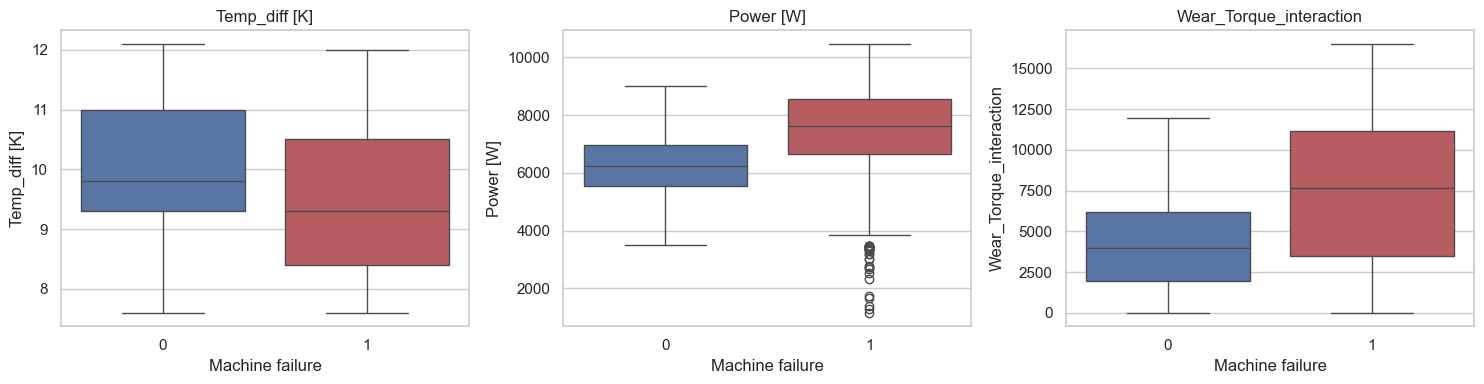

In [16]:
# Quick look at whether the new features actually separate failures from non-failures
new_features = ["Temp_diff [K]", "Power [W]", "Wear_Torque_interaction"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, new_features):
    sns.boxplot(data=df_features, x="Machine failure", y=col, hue="Machine failure",
                palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


## Cleaning up for downstream use

Drop the columns that are just identifiers (not predictive), and keep everything else
ready for the ML and DL sections.

In [17]:
def clean_for_modeling(data: pd.DataFrame) -> pd.DataFrame:
    """Drop identifier columns that shouldn't be used as model features."""
    data = data.copy()
    id_cols = ["UDI", "Product ID"]
    data = data.drop(columns=[c for c in id_cols if c in data.columns])
    return data


df_ready = clean_for_modeling(df_features)
df_ready.head()


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temp_diff [K],Power [W],Wear_Torque_interaction,Type_encoded
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,6951.590560,0.0,1
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,6826.722724,138.9,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,7749.387543,247.0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,5927.504659,276.5,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,5897.816608,360.0,0


## Save the processed dataset

This is the file the ML and DL sections below load from — raw data stays untouched,
processed data goes in its own file so we never accidentally overwrite the source.

In [18]:
import os

os.makedirs("data/processed", exist_ok=True)
df_ready.to_csv("ai4i2020_features.csv", index=False)

print("Saved:", df_ready.shape, "-> ai4i2020_features.csv")


PermissionError: [Errno 13] Permission denied: 'ai4i2020_features.csv'

## Also save this logic as a reusable module

Everything above is written to read top-to-bottom as an explanation. But `add_features`,
`clean_for_modeling`, and the feature list they produce are also needed by the ML/DL
sections below, by the Streamlit app in Part 7, and by the test suite — so this cell
writes the exact same logic out to `src/features.py` as an actual importable module.
One implementation, three consumers; no risk of the app quietly drifting from what the
model was trained on.

In [ ]:
import os

os.makedirs("src", exist_ok=True)


In [ ]:
%%writefile src/features.py
"""
Shared feature-engineering logic for the Predictive Maintenance project.

This is the single source of truth for how raw sensor readings become model
features - used by the training notebook, the Streamlit app, and the test
suite, so training and serving can never quietly drift apart.
"""

import numpy as np
import pandas as pd

TYPE_ENCODING = {"L": 0, "M": 1, "H": 2}

FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
TARGET = "Machine failure"

FEATURE_COLS = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temp_diff [K]",
    "Power [W]",
    "Wear_Torque_interaction",
    "Type_encoded",
]


def add_features(data: pd.DataFrame) -> pd.DataFrame:
    """Add engineered features to a dataframe of raw AI4I sensor readings.
    Returns a new dataframe (no in-place mutation)."""
    data = data.copy()

    data["Temp_diff [K]"] = data["Process temperature [K]"] - data["Air temperature [K]"]

    angular_speed = data["Rotational speed [rpm]"] * (2 * np.pi / 60)
    data["Power [W]"] = data["Torque [Nm]"] * angular_speed

    data["Wear_Torque_interaction"] = data["Tool wear [min]"] * data["Torque [Nm]"]

    data["Type_encoded"] = data["Type"].map(TYPE_ENCODING)

    if data["Type_encoded"].isna().any():
        bad_values = sorted(set(data.loc[data["Type_encoded"].isna(), "Type"]))
        raise ValueError(
            f"Unrecognized machine Type value(s) {bad_values} - expected one of {list(TYPE_ENCODING)}"
        )

    return data


def clean_for_modeling(data: pd.DataFrame) -> pd.DataFrame:
    """Drop identifier columns that shouldn't be used as model features."""
    data = data.copy()
    id_cols = ["UDI", "Product ID"]
    return data.drop(columns=[c for c in id_cols if c in data.columns])


def build_feature_row(air_temp, process_temp, rpm, torque, tool_wear, machine_type) -> pd.DataFrame:
    """Build a single model-ready feature row from raw sensor readings -
    what the Streamlit app calls for one machine at a time. Routes through
    the exact same add_features() used in training, just on a 1-row frame."""
    raw = pd.DataFrame([{
        "Air temperature [K]": air_temp,
        "Process temperature [K]": process_temp,
        "Rotational speed [rpm]": rpm,
        "Torque [Nm]": torque,
        "Tool wear [min]": tool_wear,
        "Type": machine_type,
    }])
    engineered = add_features(raw)
    return engineered[FEATURE_COLS]


def get_feature_columns(df: pd.DataFrame) -> list:
    """The leakage-safe feature list: everything except identifiers, the
    failure-mode flags, the target, and the raw 'Type' column."""
    drop_cols = FAILURE_MODES + [TARGET, "Type"]
    return [c for c in df.columns if c not in drop_cols]


Overwriting src/features.py


In [ ]:
from src.features import get_feature_columns, build_feature_row, TARGET, FAILURE_MODES, FEATURE_COLS

# quick round-trip check: the module's output matches what we already have in df_ready
assert get_feature_columns(df_ready) == FEATURE_COLS
print("src/features.py written and verified against df_ready.")


src/features.py written and verified against df_ready.


---
# Part 2 — Shared Modeling Setup

Both the Machine Learning and Deep Learning sections need the same three things: a
leakage-safe feature list, a train/test split, and a couple of small evaluation helpers.
Defining them **once, here**, means both tracks are guaranteed to be evaluated on the
exact same test set with the exact same metrics — which is what makes the final
"ML vs DL" comparison in Part 6 fair.

## 2.1 — Target and feature definition

**Important:** the five failure-mode flags (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) are
components of `Machine failure`, not independent causes of it — a model that sees them
is basically being shown the answer. They're excluded from the feature list, along with
the raw `Type` column (`Type_encoded` already carries that information numerically).

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from src.features import get_feature_columns, TARGET, FAILURE_MODES

df_model = pd.read_csv("ai4i2020_features.csv")

FEATURE_COLS = get_feature_columns(df_model)   # 'Type' replaced by 'Type_encoded'; excludes FAILURE_MODES + TARGET

X = df_model[FEATURE_COLS].copy()
y = df_model[TARGET].copy()

print("Features used:")
print(FEATURE_COLS)
print(f"\nClass distribution:\n{y.value_counts()}")
print(f"\nFailure rate: {y.mean():.2%}")


Features used:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temp_diff [K]', 'Power [W]', 'Wear_Torque_interaction', 'Type_encoded']

Class distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.39%


## 2.2 — Train / test split

Stratified so both sets keep the same (rare) failure ratio. `RANDOM_STATE` is fixed everywhere so both tracks split the data identically.

In [ ]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train failures: {y_train.sum()} ({y_train.mean():.2%})")
print(f"Test  failures: {y_test.sum()}  ({y_test.mean():.2%})")


Train: (8000, 9)  |  Test: (2000, 9)
Train failures: 271 (3.39%)
Test  failures: 68  (3.40%)


## 2.3 — Shared evaluation helpers

`compute_metrics` turns any set of predicted scores into the same metric row (precision,
recall, F1, PR-AUC, ROC-AUC, false-negative rate) — used by the classical models, the
MLP, and the autoencoder alike, so every row in the final comparison table means the
same thing. `find_optimal_threshold` is the same idea for picking a decision threshold
based on a minimum-precision business constraint rather than the default 0.5.

In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_curve, average_precision_score,
    roc_auc_score, f1_score, precision_score, recall_score,
)

os.makedirs("models", exist_ok=True)
os.makedirs("evaluation", exist_ok=True)

ALL_RESULTS = []  # every model's metric row lands here for the final comparison


def compute_metrics(name, y_true, y_score, threshold=0.5):
    """
    Turn a set of predicted scores (probabilities or an anomaly score - anything where
    'higher = more likely to be a failure') into one comparable metrics row.
    """
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    y_pred = (y_score >= threshold).astype(int)

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall    = recall_score(y_true, y_pred, zero_division=0)
    f1        = f1_score(y_true, y_pred, zero_division=0)
    pr_auc    = average_precision_score(y_true, y_score)
    roc_auc   = roc_auc_score(y_true, y_score)
    fn_rate   = ((y_true == 1) & (y_pred == 0)).sum() / max(y_true.sum(), 1)

    return dict(
        Model=name,
        Threshold=round(float(threshold), 4),
        Precision=round(precision, 4),
        Recall=round(recall, 4),
        F1=round(f1, 4),
        PR_AUC=round(pr_auc, 4),
        ROC_AUC=round(roc_auc, 4),
        FN_Rate=round(fn_rate, 4),
    ), y_pred


def plot_confusion(name, y_true, y_pred, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["OK", "Failure"], yticklabels=["OK", "Failure"], ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120)
    plt.show()


def find_optimal_threshold(y_true, y_score, min_precision=0.30):
    """
    Find the score threshold that maximises recall subject to precision >= min_precision.
    Falls back to the F1-optimal threshold if that constraint can't be met.
    """
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_score)
    f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-9)

    mask = precisions[:-1] >= min_precision
    if mask.any():
        candidate_recalls = np.where(mask, recalls[:-1], -1)
        best_idx = np.argmax(candidate_recalls)
    else:
        best_idx = np.argmax(f1s)

    return thresholds[best_idx], precisions[best_idx], recalls[best_idx]


print("Shared helpers ready: compute_metrics, plot_confusion, find_optimal_threshold")


Shared helpers ready: compute_metrics, plot_confusion, find_optimal_threshold


### Also save these as a reusable module

Same reasoning as `src/features.py`: the app in Part 7 needs `risk_tier` (to turn a
probability into Low/Medium/High), and the test suite needs all three functions to
verify against — so they get the same treatment.

In [ ]:
%%writefile src/modeling.py
"""
Shared model-evaluation helpers for the Predictive Maintenance project.

Used by the training notebook (ML, MLP, and Autoencoder sections all score
themselves the same way) and by the test suite, so "the metrics" always mean
the same computation everywhere.
"""

import numpy as np
from sklearn.metrics import (
    average_precision_score, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)


def compute_metrics(name, y_true, y_score, threshold=0.5):
    """
    Turn a set of predicted scores (probabilities, or an anomaly score -
    anything where 'higher = more likely to be a failure') into one
    comparable metrics row.
    """
    y_score = np.asarray(y_score)
    y_pred = (y_score >= threshold).astype(int)

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    pr_auc = average_precision_score(y_true, y_score)
    roc_auc = roc_auc_score(y_true, y_score)
    fn_rate = ((np.asarray(y_true) == 1) & (y_pred == 0)).sum() / max(np.asarray(y_true).sum(), 1)

    row = dict(
        Model=name,
        Threshold=round(float(threshold), 4),
        Precision=round(float(precision), 4),
        Recall=round(float(recall), 4),
        F1=round(float(f1), 4),
        PR_AUC=round(float(pr_auc), 4),
        ROC_AUC=round(float(roc_auc), 4),
        FN_Rate=round(float(fn_rate), 4),
    )
    return row, y_pred


def find_optimal_threshold(y_true, y_score, min_precision=0.30):
    """
    Find the score threshold that maximises recall subject to
    precision >= min_precision. Falls back to the F1-optimal threshold
    if that constraint can't be met.
    """
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_score)
    f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-9)

    mask = precisions[:-1] >= min_precision
    if mask.any():
        candidate_recalls = np.where(mask, recalls[:-1], -1)
        best_idx = np.argmax(candidate_recalls)
    else:
        best_idx = np.argmax(f1s)

    return thresholds[best_idx], precisions[best_idx], recalls[best_idx]


def risk_tier(probability, threshold):
    """Low / Medium / High risk banding - shared by the app and reporting code."""
    if probability < 0.30:
        return "Low", "Continue normal operation"
    elif probability < threshold:
        return "Medium", "Schedule an inspection soon"
    else:
        return "High", "Immediate inspection required"


Overwriting src/modeling.py


In [ ]:
from src.modeling import compute_metrics as _module_compute_metrics

# quick round-trip check: the module's version agrees with the notebook's own
_dummy_true = [0, 0, 1, 1]
_dummy_score = [0.1, 0.4, 0.6, 0.9]
_row_a, _ = compute_metrics("x", _dummy_true, _dummy_score, 0.5)
_row_b, _ = _module_compute_metrics("x", _dummy_true, _dummy_score, 0.5)
assert _row_a == _row_b
print("src/modeling.py written and verified against the notebook's own compute_metrics.")


src/modeling.py written and verified against the notebook's own compute_metrics.


## 2.4 — Save feature reference statistics (for monitoring later)

The Streamlit app in Part 7 needs something to compare *live* inputs against, to flag
values that look out of distribution ("does this look like anything the model was
actually trained on?"). Saving the training set's per-feature statistics here, once,
means the app doesn't need to load the full training data just to do that check.

In [ ]:
import json

feature_reference_stats = {}
for col in FEATURE_COLS:
    feature_reference_stats[col] = {
        "min": float(X_train[col].min()),
        "max": float(X_train[col].max()),
        "mean": float(X_train[col].mean()),
        "std": float(X_train[col].std()),
        "p01": float(X_train[col].quantile(0.01)),
        "p99": float(X_train[col].quantile(0.99)),
    }

with open("models/feature_reference_stats.json", "w") as f:
    json.dump(feature_reference_stats, f, indent=2)

print("Saved -> models/feature_reference_stats.json")


Saved -> models/feature_reference_stats.json


---
# Part 3 — Machine Learning Track

Logistic Regression baseline → Decision Tree → Random Forest → Gradient Boosting,
with class-weighting, cross-validation, hyperparameter tuning, threshold optimisation,
and SHAP explainability.

## 3.1 — Imports

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import joblib
import json

print("ML imports OK")


ML imports OK


## 3.2 — Model wrapper

Fits an estimator, scores it with the shared `compute_metrics` helper, prints a
classification report, and draws the confusion matrix — one call per model.

In [ ]:
def evaluate_model(name, estimator, X_tr, y_tr, X_te, y_te, threshold=0.5, results_store=None):
    """Fit + evaluate a scikit-learn estimator, using the shared metric helpers."""
    estimator.fit(X_tr, y_tr)

    if hasattr(estimator, "predict_proba"):
        y_prob = estimator.predict_proba(X_te)[:, 1]
    else:
        y_prob = estimator.decision_function(X_te)

    row, y_pred = compute_metrics(name, y_te, y_prob, threshold=threshold)

    if results_store is not None:
        results_store.append(row)

    print(f"\n{'=' * 60}")
    print(f"  {name}  (threshold={threshold})")
    print(f"{'=' * 60}")
    print(classification_report(y_te, y_pred, target_names=["OK", "Failure"]))
    print(f"PR-AUC : {row['PR_AUC']:.4f}   ROC-AUC: {row['ROC_AUC']:.4f}   FN-rate: {row['FN_Rate']:.4f}")

    plot_confusion(name, y_te, y_pred, save_path=f"evaluation/{name.replace(' ', '_')}_cm.png")

    return row, estimator, y_prob


## 3.3 — Logistic Regression (baseline)


  LR (default)  (threshold=0.5)
              precision    recall  f1-score   support

          OK       0.97      1.00      0.98      1932
     Failure       0.57      0.18      0.27        68

    accuracy                           0.97      2000
   macro avg       0.77      0.59      0.63      2000
weighted avg       0.96      0.97      0.96      2000

PR-AUC : 0.4686   ROC-AUC: 0.9258   FN-rate: 0.8235


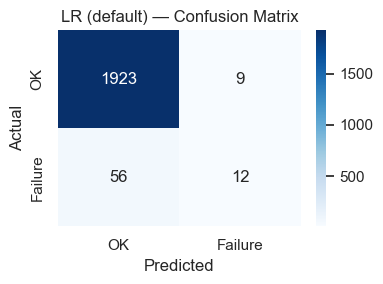

In [ ]:
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

lr_row, lr_fitted, lr_prob = evaluate_model(
    "LR (default)", lr_pipe, X_train, y_train, X_test, y_test, results_store=ALL_RESULTS
)


### Logistic Regression with `class_weight='balanced'`

The class-weighting experiment required by the project — same model, but the minority
(failure) class is upweighted during training instead of left at its natural ~3% share.


  LR (balanced)  (threshold=0.5)
              precision    recall  f1-score   support

          OK       1.00      0.86      0.92      1932
     Failure       0.18      0.88      0.30        68

    accuracy                           0.86      2000
   macro avg       0.59      0.87      0.61      2000
weighted avg       0.97      0.86      0.90      2000

PR-AUC : 0.4336   ROC-AUC: 0.9393   FN-rate: 0.1176


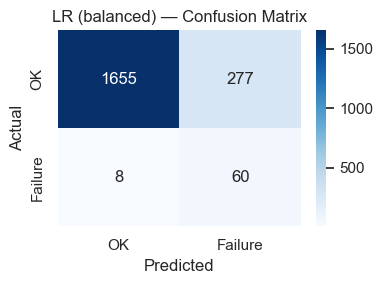

In [ ]:
lr_bal_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])

lr_bal_row, lr_bal_fitted, lr_bal_prob = evaluate_model(
    "LR (balanced)", lr_bal_pipe, X_train, y_train, X_test, y_test, results_store=ALL_RESULTS
)


## 3.4 — Decision Tree


  Decision Tree  (threshold=0.5)
              precision    recall  f1-score   support

          OK       0.99      0.95      0.97      1932
     Failure       0.39      0.82      0.53        68

    accuracy                           0.95      2000
   macro avg       0.69      0.89      0.75      2000
weighted avg       0.97      0.95      0.96      2000

PR-AUC : 0.7731   ROC-AUC: 0.8568   FN-rate: 0.1765


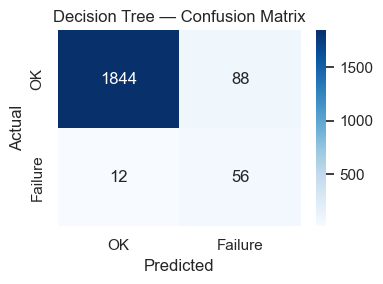

In [ ]:
dt_clf = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE)

dt_row, dt_fitted, dt_prob = evaluate_model(
    "Decision Tree", dt_clf, X_train, y_train, X_test, y_test, results_store=ALL_RESULTS
)


## 3.5 — Random Forest


  Random Forest  (threshold=0.5)
              precision    recall  f1-score   support

          OK       0.99      1.00      0.99      1932
     Failure       0.96      0.74      0.83        68

    accuracy                           0.99      2000
   macro avg       0.98      0.87      0.91      2000
weighted avg       0.99      0.99      0.99      2000

PR-AUC : 0.8693   ROC-AUC: 0.9666   FN-rate: 0.2647


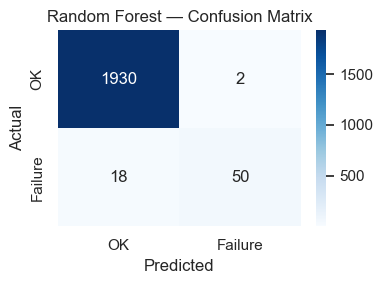

In [ ]:
rf_clf = RandomForestClassifier(
    n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)

rf_row, rf_fitted, rf_prob = evaluate_model(
    "Random Forest", rf_clf, X_train, y_train, X_test, y_test, results_store=ALL_RESULTS
)


## 3.6 — Gradient Boosting


  Gradient Boosting  (threshold=0.5)
              precision    recall  f1-score   support

          OK       0.99      1.00      1.00      1932
     Failure       0.96      0.79      0.87        68

    accuracy                           0.99      2000
   macro avg       0.98      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000

PR-AUC : 0.8928   ROC-AUC: 0.9663   FN-rate: 0.2059


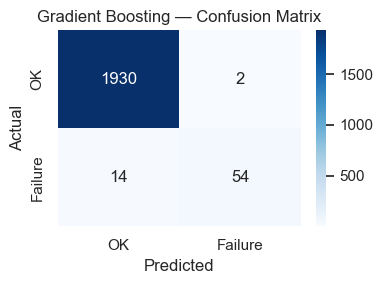

In [ ]:
gb_clf = GradientBoostingClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=RANDOM_STATE
)

gb_row, gb_fitted, gb_prob = evaluate_model(
    "Gradient Boosting", gb_clf, X_train, y_train, X_test, y_test, results_store=ALL_RESULTS
)


## 3.7 — Cross-validation (PR-AUC)

5-fold stratified CV, scored on average precision (PR-AUC) since that's the metric that
actually matters under this much class imbalance.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_models = {
    "LR (balanced)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=RANDOM_STATE
    ),
}

print(f"5-Fold CV — PR-AUC (average_precision)\n{'-' * 50}")
cv_results = {}
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:<22}  mean={scores.mean():.4f}  std={scores.std():.4f}  folds={np.round(scores, 4)}")


5-Fold CV — PR-AUC (average_precision)
--------------------------------------------------
LR (balanced)           mean=0.4582  std=0.0405  folds=[0.5148 0.4956 0.4397 0.4063 0.4347]
Decision Tree           mean=0.7941  std=0.0526  folds=[0.8635 0.7147 0.7678 0.7858 0.8384]
Random Forest           mean=0.8883  std=0.0322  folds=[0.9302 0.8363 0.87   0.9038 0.901 ]
Gradient Boosting       mean=0.8876  std=0.0358  folds=[0.9137 0.8205 0.8854 0.9209 0.8975]


## 3.8 — Hyperparameter tuning (Random Forest & Gradient Boosting)

Grid search scored on PR-AUC, since that's the metric we actually care about here.

In [ ]:
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2],
}

rf_gs = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    rf_param_grid, cv=cv, scoring="average_precision", n_jobs=-1, verbose=0,
)
rf_gs.fit(X_train, y_train)
print("RF best params  :", rf_gs.best_params_)
print("RF best CV PR-AUC:", round(rf_gs.best_score_, 4))


RF best params  : {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
RF best CV PR-AUC: 0.8957


In [ ]:
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 4, 5],
}

gb_gs = GridSearchCV(
    GradientBoostingClassifier(subsample=0.8, random_state=RANDOM_STATE),
    gb_param_grid, cv=cv, scoring="average_precision", n_jobs=-1, verbose=0,
)
gb_gs.fit(X_train, y_train)
print("GB best params  :", gb_gs.best_params_)
print("GB best CV PR-AUC:", round(gb_gs.best_score_, 4))


GB best params  : {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}
GB best CV PR-AUC: 0.9133



  RF (tuned)  (threshold=0.5)
              precision    recall  f1-score   support

          OK       0.99      1.00      0.99      1932
     Failure       0.94      0.75      0.84        68

    accuracy                           0.99      2000
   macro avg       0.97      0.87      0.92      2000
weighted avg       0.99      0.99      0.99      2000

PR-AUC : 0.8654   ROC-AUC: 0.9800   FN-rate: 0.2500


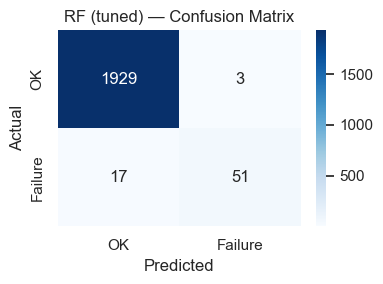


  GB (tuned)  (threshold=0.5)
              precision    recall  f1-score   support

          OK       0.99      1.00      1.00      1932
     Failure       0.98      0.78      0.87        68

    accuracy                           0.99      2000
   macro avg       0.99      0.89      0.93      2000
weighted avg       0.99      0.99      0.99      2000

PR-AUC : 0.8925   ROC-AUC: 0.9667   FN-rate: 0.2206


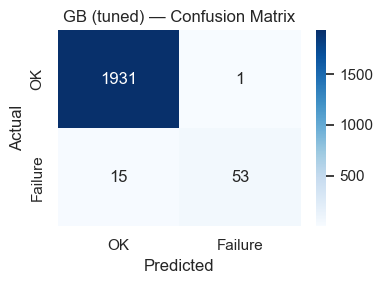

In [ ]:
rf_tuned_row, rf_tuned, rf_tuned_prob = evaluate_model(
    "RF (tuned)", rf_gs.best_estimator_, X_train, y_train, X_test, y_test, results_store=ALL_RESULTS
)

gb_tuned_row, gb_tuned, gb_tuned_prob = evaluate_model(
    "GB (tuned)", gb_gs.best_estimator_, X_train, y_train, X_test, y_test, results_store=ALL_RESULTS
)


## 3.9 — Threshold optimisation

The default 0.5 threshold is arbitrary — for predictive maintenance, missing a real
failure (a false negative) is usually far more costly than one extra inspection (a
false positive). `find_optimal_threshold` looks for the threshold that maximises recall
while keeping precision above a floor we're willing to tolerate operationally.

In [ ]:
thresholds_by_model = {}
for model_name, y_prob_arr in [("RF (tuned)", rf_tuned_prob), ("GB (tuned)", gb_tuned_prob)]:
    opt_thresh, opt_prec, opt_rec = find_optimal_threshold(y_test, y_prob_arr, min_precision=0.30)
    thresholds_by_model[model_name] = opt_thresh
    print(f"{model_name}  optimal threshold={opt_thresh:.3f}  precision={opt_prec:.3f}  recall={opt_rec:.3f}")


RF (tuned)  optimal threshold=0.079  precision=0.300  recall=0.941
GB (tuned)  optimal threshold=0.010  precision=0.309  recall=0.941


RF (tuned + optimal threshold):
              precision    recall  f1-score   support

          OK       1.00      0.92      0.96      1932
     Failure       0.30      0.94      0.46        68

    accuracy                           0.92      2000
   macro avg       0.65      0.93      0.71      2000
weighted avg       0.97      0.92      0.94      2000



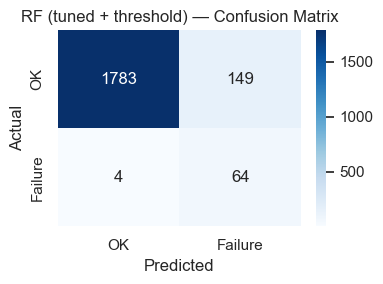


GB (tuned + optimal threshold):
              precision    recall  f1-score   support

          OK       1.00      0.93      0.96      1932
     Failure       0.31      0.94      0.47        68

    accuracy                           0.93      2000
   macro avg       0.65      0.93      0.71      2000
weighted avg       0.97      0.93      0.94      2000



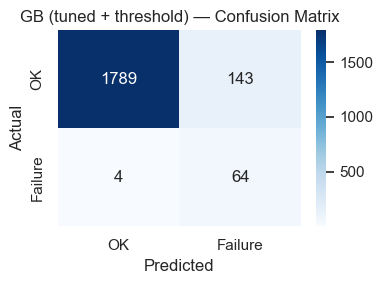

In [ ]:
# Evaluate RF (tuned) and GB (tuned) at their own optimal thresholds - the
# "high recall" operating point each would actually run at in production.
opt_thresh_rf = thresholds_by_model["RF (tuned)"]
opt_thresh_gb = thresholds_by_model["GB (tuned)"]

opt_row_rf, y_pred_opt_rf = compute_metrics("RF (tuned+threshold)", y_test, rf_tuned_prob, threshold=opt_thresh_rf)
opt_row_gb, y_pred_opt_gb = compute_metrics("GB (tuned+threshold)", y_test, gb_tuned_prob, threshold=opt_thresh_gb)
ALL_RESULTS.append(opt_row_rf)
ALL_RESULTS.append(opt_row_gb)

print("RF (tuned + optimal threshold):")
print(classification_report(y_test, y_pred_opt_rf, target_names=["OK", "Failure"]))
plot_confusion("RF (tuned + threshold)", y_test, y_pred_opt_rf, save_path="evaluation/RF_tuned_threshold_cm.png")

print("\nGB (tuned + optimal threshold):")
print(classification_report(y_test, y_pred_opt_gb, target_names=["OK", "Failure"]))
plot_confusion("GB (tuned + threshold)", y_test, y_pred_opt_gb, save_path="evaluation/GB_tuned_threshold_cm.png")


## 3.10 — Precision-Recall curves (all models)

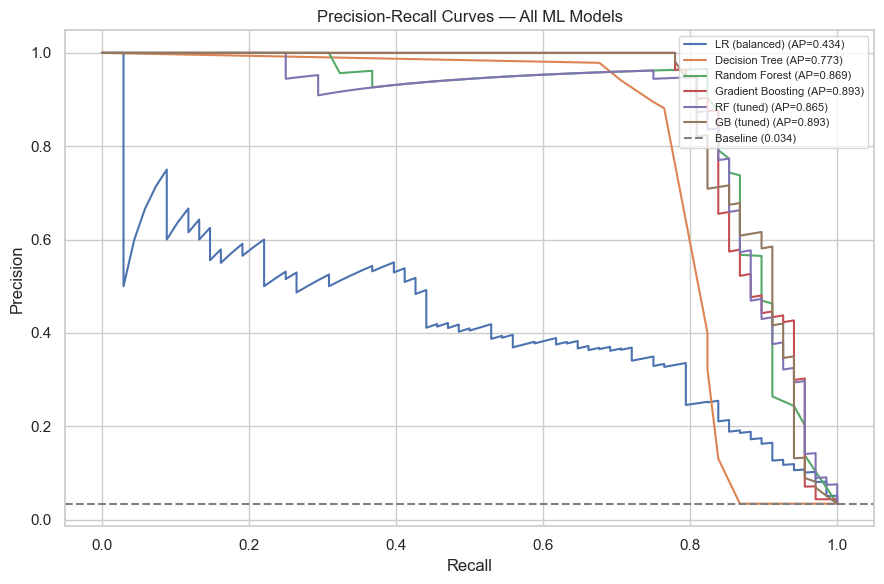

In [ ]:
prob_dict = {
    "LR (balanced)": lr_bal_fitted.predict_proba(X_test)[:, 1],
    "Decision Tree": dt_fitted.predict_proba(X_test)[:, 1],
    "Random Forest": rf_fitted.predict_proba(X_test)[:, 1],
    "Gradient Boosting": gb_fitted.predict_proba(X_test)[:, 1],
    "RF (tuned)": rf_tuned.predict_proba(X_test)[:, 1],
    "GB (tuned)": gb_tuned.predict_proba(X_test)[:, 1],
}

fig, ax = plt.subplots(figsize=(9, 6))
for name, probs in prob_dict.items():
    p, r, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    ax.plot(r, p, label=f"{name} (AP={ap:.3f})")

baseline = y_test.mean()
ax.axhline(baseline, linestyle="--", color="grey", label=f"Baseline ({baseline:.3f})")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves — All ML Models")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig("evaluation/pr_curves.png", dpi=150)
plt.show()


## 3.11 — ML model comparison table

In [ ]:
ml_comparison_df = pd.DataFrame(ALL_RESULTS).sort_values("PR_AUC", ascending=False).reset_index(drop=True)

print("=" * 80)
print("ML COMPARISON TABLE")
print("=" * 80)
print(ml_comparison_df.to_string(index=False))
print("=" * 80)

ml_comparison_df.to_csv("evaluation/ml_comparison.csv", index=False)
print("\nSaved -> evaluation/ml_comparison.csv")


ML COMPARISON TABLE
               Model  Threshold  Precision  Recall     F1  PR_AUC  ROC_AUC  FN_Rate
   Gradient Boosting     0.5000     0.9643  0.7941 0.8710  0.8928   0.9663   0.2059
GB (tuned+threshold)     0.0097     0.3092  0.9412 0.4655  0.8925   0.9667   0.0588
          GB (tuned)     0.5000     0.9815  0.7794 0.8689  0.8925   0.9667   0.2206
       Random Forest     0.5000     0.9615  0.7353 0.8333  0.8693   0.9666   0.2647
          RF (tuned)     0.5000     0.9444  0.7500 0.8361  0.8654   0.9800   0.2500
RF (tuned+threshold)     0.0794     0.3005  0.9412 0.4555  0.8654   0.9800   0.0588
       Decision Tree     0.5000     0.3889  0.8235 0.5283  0.7731   0.8568   0.1765
        LR (default)     0.5000     0.5714  0.1765 0.2697  0.4686   0.9258   0.8235
       LR (balanced)     0.5000     0.1780  0.8824 0.2963  0.4336   0.9393   0.1176

Saved -> evaluation/ml_comparison.csv


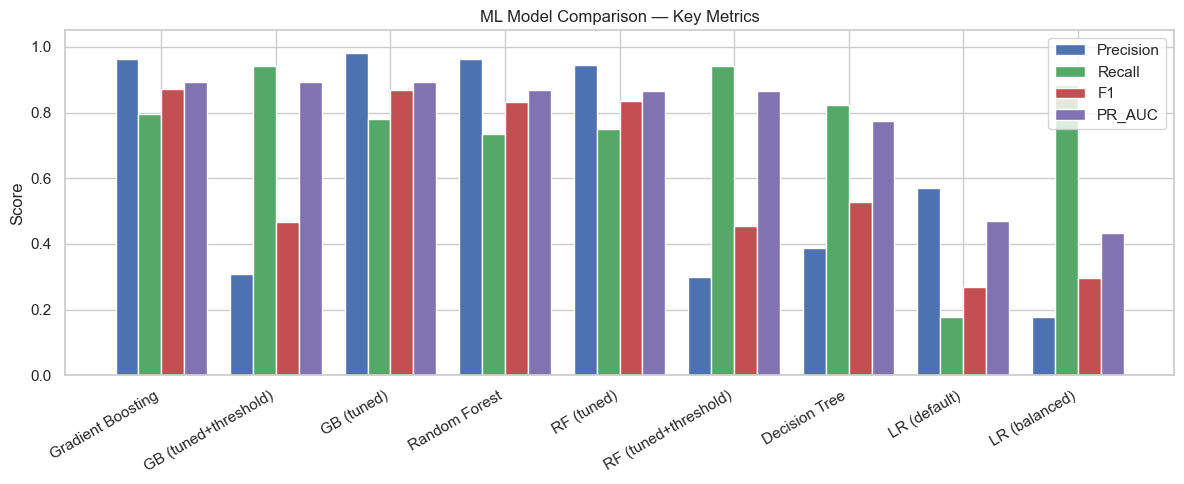

In [ ]:
plot_df = ml_comparison_df.set_index("Model")[["Precision", "Recall", "F1", "PR_AUC"]]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(plot_df))
width = 0.20
offsets = [-1.5, -0.5, 0.5, 1.5]
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]

for i, (col, color) in enumerate(zip(plot_df.columns, colors)):
    ax.bar(x + offsets[i] * width, plot_df[col], width, label=col, color=color)

ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=30, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("ML Model Comparison — Key Metrics")
ax.legend()
plt.tight_layout()
plt.savefig("evaluation/model_comparison_bar.png", dpi=150)
plt.show()


## 3.12 — SHAP explainability (best model)

Using the tuned Gradient Boosting model, since it's the strongest of the tree-based
models and SHAP's `TreeExplainer` is fast and exact for tree ensembles.

In [ ]:
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("shap is not installed — run `pip install shap` to enable this section.")

best_model = gb_tuned
best_name = "GB (tuned)"

if SHAP_AVAILABLE:
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_test)

    # shap_values can come back as a list of per-class arrays, or a single 3D array,
    # depending on the shap version - handle both so this doesn't break on upgrade.
    if isinstance(shap_values, list):
        sv_failure = shap_values[1]
    elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
        sv_failure = shap_values[:, :, 1]
    else:
        sv_failure = shap_values

    print(f"SHAP computed for {best_name} on {len(X_test)} test samples")


SHAP computed for GB (tuned) on 2000 test samples


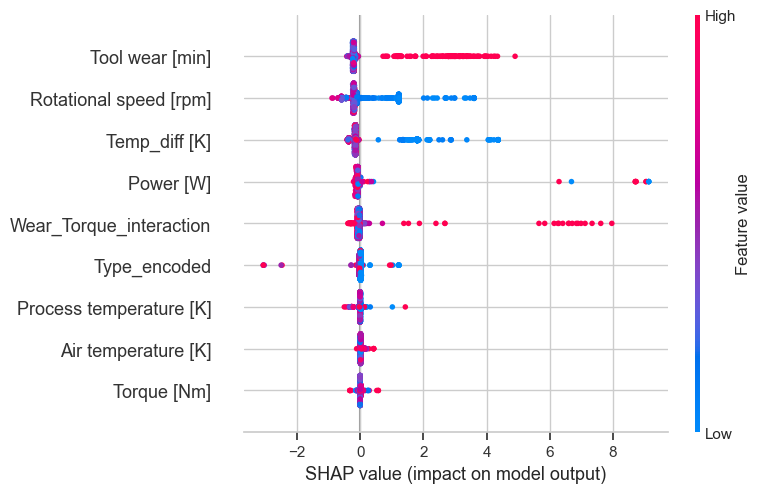

In [ ]:
if SHAP_AVAILABLE:
    shap.plots.beeswarm(
        shap.Explanation(
            values=sv_failure,
            base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list)
                        else explainer.expected_value,
            data=X_test.values,
            feature_names=FEATURE_COLS,
        ),
        show=False,
    )
    plt.tight_layout()
    plt.savefig("evaluation/shap_beeswarm.png", dpi=150, bbox_inches="tight")
    plt.show()


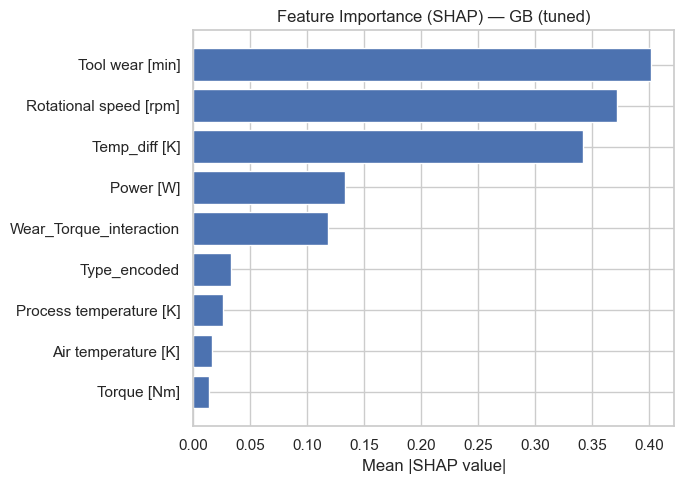

Saved -> evaluation/shap_feature_importance.csv


In [ ]:
if SHAP_AVAILABLE:
    mean_abs_shap = np.abs(sv_failure).mean(axis=0)
    shap_df = pd.DataFrame({"Feature": FEATURE_COLS, "Mean |SHAP|": mean_abs_shap})
    shap_df = shap_df.sort_values("Mean |SHAP|", ascending=True)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(shap_df["Feature"], shap_df["Mean |SHAP|"], color="#4C72B0")
    ax.set_xlabel("Mean |SHAP value|")
    ax.set_title(f"Feature Importance (SHAP) — {best_name}")
    plt.tight_layout()
    plt.savefig("evaluation/shap_bar.png", dpi=150)
    plt.show()

    shap_df.sort_values("Mean |SHAP|", ascending=False).to_csv(
        "evaluation/shap_feature_importance.csv", index=False
    )
    print("Saved -> evaluation/shap_feature_importance.csv")


## 3.13 — Class-weighting experiment summary

In [ ]:
cw_rows = [r for r in ALL_RESULTS if "LR" in r["Model"]]
cw_df = pd.DataFrame(cw_rows)
print("Class-weighting effect on Logistic Regression:")
print(cw_df[["Model", "Precision", "Recall", "F1", "PR_AUC", "FN_Rate"]].to_string(index=False))


Class-weighting effect on Logistic Regression:
        Model  Precision  Recall     F1  PR_AUC  FN_Rate
 LR (default)     0.5714  0.1765 0.2697  0.4686   0.8235
LR (balanced)     0.1780  0.8824 0.2963  0.4336   0.1176


## 3.14 — Save the best ML model

In [ ]:
# Deploy gb_tuned as the estimator, but use ITS OWN tuned-threshold metrics row
# for the metadata - not the default-threshold row. The threshold is what the
# Streamlit app will actually use to turn a probability into a decision, so it
# has to be the business-tuned one, not the arbitrary 0.5 default.
DEPLOY_METRICS_ROW = "GB (tuned+threshold)"

joblib.dump(best_model, "models/best_model.pkl")
print(f"Best ML model ({best_name}) saved -> models/best_model.pkl")

ml_best_row = next(r for r in ALL_RESULTS if r["Model"] == DEPLOY_METRICS_ROW)
with open("models/best_model_meta.json", "w") as f:
    json.dump({"model_name": best_name, "features": FEATURE_COLS, "metrics": ml_best_row}, f, indent=2)
print(f"Metadata saved -> models/best_model_meta.json  (threshold={ml_best_row['Threshold']})")


Best ML model (GB (tuned)) saved -> models/best_model.pkl
Metadata saved -> models/best_model_meta.json  (threshold=0.0097)


## 3.15 — ML section summary

In [ ]:
print("=" * 80)
print("ML RESULTS SUMMARY")
print("=" * 80)
print(ml_comparison_df[["Model", "Precision", "Recall", "F1", "PR_AUC", "FN_Rate"]].to_string(index=False))
print("=" * 80)


ML RESULTS SUMMARY
               Model  Precision  Recall     F1  PR_AUC  FN_Rate
   Gradient Boosting     0.9643  0.7941 0.8710  0.8928   0.2059
GB (tuned+threshold)     0.3092  0.9412 0.4655  0.8925   0.0588
          GB (tuned)     0.9815  0.7794 0.8689  0.8925   0.2206
       Random Forest     0.9615  0.7353 0.8333  0.8693   0.2647
          RF (tuned)     0.9444  0.7500 0.8361  0.8654   0.2500
RF (tuned+threshold)     0.3005  0.9412 0.4555  0.8654   0.0588
       Decision Tree     0.3889  0.8235 0.5283  0.7731   0.1765
        LR (default)     0.5714  0.1765 0.2697  0.4686   0.8235
       LR (balanced)     0.1780  0.8824 0.2963  0.4336   0.1176


---
# Part 4 — Deep Learning Track (I): MLP Classifier

A feed-forward neural network on the same tabular features, using the same
`X_train` / `X_test` / `y_train` / `y_test` split from Part 2 — so its test-set score
is directly comparable to the ML models above.

Needs `torch` installed (`pip install torch`).

## 4.1 — Imports & device

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


## 4.2 — Train / validation split + scaling

The MLP gets its own validation split (carved out of the shared `X_train`) purely for
early stopping — the shared `X_test` from Part 2 is left untouched so every model in
this notebook is judged on the exact same held-out rows.

In [ ]:
X_dl_train, X_dl_val, y_dl_train, y_dl_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train
)

print("DL train:", X_dl_train.shape[0])
print("DL val  :", X_dl_val.shape[0])
print("Test    :", X_test.shape[0], " (shared with the ML section)")

# Neural nets need scaled inputs - tree models don't, which is why this scaler
# is separate from anything in Part 3.
mlp_scaler = StandardScaler()
X_dl_train_s = mlp_scaler.fit_transform(X_dl_train)
X_dl_val_s   = mlp_scaler.transform(X_dl_val)
X_test_s     = mlp_scaler.transform(X_test)

print("Processed train:", X_dl_train_s.shape)
print("Processed val  :", X_dl_val_s.shape)
print("Processed test :", X_test_s.shape)


DL train: 6000
DL val  : 2000
Test    : 2000  (shared with the ML section)
Processed train: (6000, 9)
Processed val  : (2000, 9)
Processed test : (2000, 9)


In [ ]:
def to_loader(X_arr, y_arr, batch_size=64, shuffle=False):
    X_t = torch.tensor(X_arr, dtype=torch.float32)
    y_t = torch.tensor(y_arr.values, dtype=torch.float32)
    return DataLoader(TensorDataset(X_t, y_t), batch_size=batch_size, shuffle=shuffle)


train_loader = to_loader(X_dl_train_s, y_dl_train, shuffle=True)
val_loader   = to_loader(X_dl_val_s, y_dl_val)
test_loader  = to_loader(X_test_s, y_test)


## 4.3 — Model definition

Input size is read from the data (`X_dl_train_s.shape[1]`) rather than hardcoded, so
this doesn't silently break if the feature list ever changes upstream.

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.relu = nn.LeakyReLU(0.01)
        self.fc2 = nn.Linear(64, 48)
        self.fc3 = nn.Linear(48, 32)
        self.fc4 = nn.Linear(32, 1)

    def forward(self, x):
        out = self.relu(self.fc1(x))
        out = self.relu(self.fc2(out))
        out = self.relu(self.fc3(out))
        out = self.fc4(out)
        return out


input_dim = X_dl_train_s.shape[1]
mlp_model = MLP(input_dim).to(device)
print(mlp_model)


MLP(
  (fc1): Linear(in_features=9, out_features=64, bias=True)
  (relu): LeakyReLU(negative_slope=0.01)
  (fc2): Linear(in_features=64, out_features=48, bias=True)
  (fc3): Linear(in_features=48, out_features=32, bias=True)
  (fc4): Linear(in_features=32, out_features=1, bias=True)
)


## 4.4 — Loss, optimiser, class weighting

Same idea as `class_weight='balanced'` on the classical models: `pos_weight` tells the
loss function to penalise missed failures harder than false alarms, since failures are ~3% of the data.

In [ ]:
n_negative = (y_dl_train == 0).sum()
n_positive = (y_dl_train == 1).sum()
pos_weight = torch.tensor([n_negative / n_positive], dtype=torch.float32, device=device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(mlp_model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

print("pos_weight:", pos_weight.item())


pos_weight: 28.556650161743164


## 4.5 — Training loop (early stopping + LR scheduling)

In [ ]:
epochs = 50
patience = 5
best_val_loss = float("inf")
counter = 0
DECISION_THRESHOLD = 0.3  # a first pass threshold; tuned properly in 4.7

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(epochs):
    # ---- training ----
    mlp_model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).float().view(-1, 1)

        optimizer.zero_grad()
        outputs = mlp_model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * X_batch.size(0)
        preds = (torch.sigmoid(outputs) >= DECISION_THRESHOLD).float()
        train_correct += (preds == y_batch).sum().item()
        train_total += y_batch.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # ---- validation ----
    mlp_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device).float().view(-1, 1)

            outputs = mlp_model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)

            preds = (torch.sigmoid(outputs) >= DECISION_THRESHOLD).float()
            val_correct += (preds == y_batch).sum().item()
            val_total += y_batch.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    train_losses.append(train_loss); val_losses.append(val_loss)
    train_accs.append(train_acc); val_accs.append(val_acc)

    scheduler.step(val_loss)

    print(f"Epoch [{epoch+1}/{epochs}]  Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.4f}  "
          f"Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        best_state = {k: v.clone() for k, v in mlp_model.state_dict().items()}
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping triggered!")
            break

mlp_model.load_state_dict(best_state)  # roll back to the best epoch, not just the last one


Epoch [1/50]  Train Loss: 1.0633  Train Acc: 0.2125  Val Loss: 0.8993  Val Acc: 0.5450
Epoch [2/50]  Train Loss: 0.7204  Train Acc: 0.6697  Val Loss: 0.7811  Val Acc: 0.6495
Epoch [3/50]  Train Loss: 0.6182  Train Acc: 0.7335  Val Loss: 0.7485  Val Acc: 0.7680
Epoch [4/50]  Train Loss: 0.5736  Train Acc: 0.7802  Val Loss: 0.7043  Val Acc: 0.7920
Epoch [5/50]  Train Loss: 0.5172  Train Acc: 0.7840  Val Loss: 0.6900  Val Acc: 0.8195
Epoch [6/50]  Train Loss: 0.4782  Train Acc: 0.8110  Val Loss: 0.6355  Val Acc: 0.8220
Epoch [7/50]  Train Loss: 0.4458  Train Acc: 0.8280  Val Loss: 0.6384  Val Acc: 0.8425
Epoch [8/50]  Train Loss: 0.4386  Train Acc: 0.8385  Val Loss: 0.5931  Val Acc: 0.8190
Epoch [9/50]  Train Loss: 0.4145  Train Acc: 0.8518  Val Loss: 0.5727  Val Acc: 0.8465
Epoch [10/50]  Train Loss: 0.3932  Train Acc: 0.8502  Val Loss: 0.6248  Val Acc: 0.8560
Epoch [11/50]  Train Loss: 0.3736  Train Acc: 0.8710  Val Loss: 0.5762  Val Acc: 0.8480
Epoch [12/50]  Train Loss: 0.3706  Train 

<All keys matched successfully>

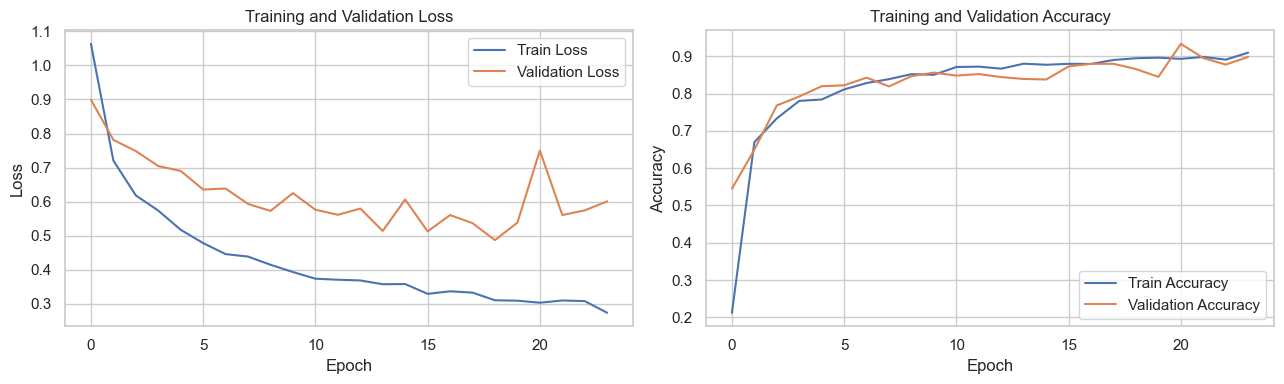

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(train_losses, label="Train Loss")
axes[0].plot(val_losses, label="Validation Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()

axes[1].plot(train_accs, label="Train Accuracy")
axes[1].plot(val_accs, label="Validation Accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("evaluation/mlp_training_curves.png", dpi=120)
plt.show()


## 4.6 — Test set evaluation

Same metric set as the ML section (precision, recall, F1, PR-AUC, ROC-AUC) so this
row drops straight into the final comparison table in Part 6.

              precision    recall  f1-score   support

  No Failure       1.00      0.92      0.96      1932
     Failure       0.28      0.91      0.43        68

    accuracy                           0.92      2000
   macro avg       0.64      0.92      0.69      2000
weighted avg       0.97      0.92      0.94      2000

PR-AUC : 0.7054   ROC-AUC: 0.9772


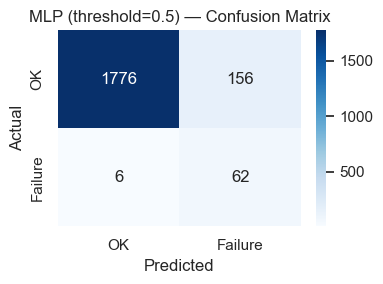

In [ ]:
mlp_model.eval()
mlp_test_probs = []

with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(device)
        probs = torch.sigmoid(mlp_model(X_batch))
        mlp_test_probs.extend(probs.cpu().numpy().flatten())

mlp_test_probs = np.array(mlp_test_probs)

mlp_row_default, mlp_pred_default = compute_metrics("MLP (default thr)", y_test, mlp_test_probs, threshold=0.5)
print(classification_report(y_test, mlp_pred_default, target_names=["No Failure", "Failure"]))
print(f"PR-AUC : {mlp_row_default['PR_AUC']:.4f}   ROC-AUC: {mlp_row_default['ROC_AUC']:.4f}")

plot_confusion("MLP (threshold=0.5)", y_test, mlp_pred_default, save_path="evaluation/mlp_cm.png")


## 4.7 — Threshold optimisation for the MLP

Same `find_optimal_threshold` helper used for the ML models, applied to the MLP's own validation set.

MLP optimal threshold=0.611  precision=0.301  recall=0.853

MLP at tuned threshold:
              precision    recall  f1-score   support

  No Failure       1.00      0.94      0.97      1932
     Failure       0.34      0.90      0.49        68

    accuracy                           0.94      2000
   macro avg       0.67      0.92      0.73      2000
weighted avg       0.97      0.94      0.95      2000



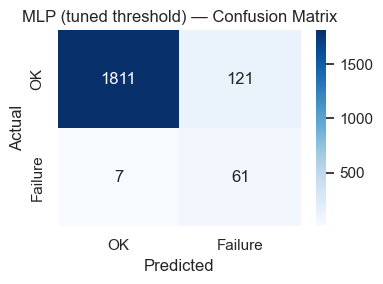

In [ ]:
mlp_val_probs = []
with torch.no_grad():
    for X_batch, _ in val_loader:
        X_batch = X_batch.to(device)
        probs = torch.sigmoid(mlp_model(X_batch))
        mlp_val_probs.extend(probs.cpu().numpy().flatten())
mlp_val_probs = np.array(mlp_val_probs)

mlp_opt_thresh, mlp_opt_prec, mlp_opt_rec = find_optimal_threshold(
    y_dl_val, mlp_val_probs, min_precision=0.30
)
print(f"MLP optimal threshold={mlp_opt_thresh:.3f}  precision={mlp_opt_prec:.3f}  recall={mlp_opt_rec:.3f}")

mlp_row_tuned, mlp_pred_tuned = compute_metrics("MLP (tuned threshold)", y_test, mlp_test_probs, threshold=mlp_opt_thresh)
ALL_RESULTS.append(mlp_row_default)
ALL_RESULTS.append(mlp_row_tuned)

print("\nMLP at tuned threshold:")
print(classification_report(y_test, mlp_pred_tuned, target_names=["No Failure", "Failure"]))
plot_confusion("MLP (tuned threshold)", y_test, mlp_pred_tuned, save_path="evaluation/mlp_tuned_cm.png")


## 4.8 — Save the MLP

In [ ]:
torch.save(mlp_model.state_dict(), "models/mlp_state_dict.pt")
with open("models/mlp_meta.json", "w") as f:
    json.dump({
        "input_dim": input_dim,
        "features": FEATURE_COLS,
        "default_threshold_metrics": mlp_row_default,
        "tuned_threshold_metrics": mlp_row_tuned,
    }, f, indent=2)
print("MLP saved -> models/mlp_state_dict.pt")
print("Metadata saved -> models/mlp_meta.json")


MLP saved -> models/mlp_state_dict.pt
Metadata saved -> models/mlp_meta.json


---
# Part 5 — Deep Learning Track (II): Autoencoder for Anomaly Detection

This is the piece the project brief explicitly requires alongside the MLP: *"Autoencoder
for unsupervised anomaly detection"* + *"Compare supervised failure prediction with
anomaly score."* It wasn't in the original notebook, so it's new here.

**The idea:** train an autoencoder to reconstruct only *normal* (non-failure) sensor
readings. It gets good at reconstructing healthy behaviour and, because it's never seen
a failure during training, it should reconstruct failure rows noticeably worse. That
reconstruction error becomes an unsupervised "anomaly score" — no failure labels are
used for training, only for picking a threshold and for evaluation afterwards.

## 5.1 — Isolate normal-only training data

The autoencoder only ever trains on rows where `Machine failure == 0` — showing it a
failure during training would defeat the point.

In [ ]:
normal_mask = (y_dl_train == 0)
X_normal = X_dl_train_s[normal_mask.values]

# A small held-out slice of *normal* data, just to monitor reconstruction loss during
# training (early stopping) - separate from the val set used for threshold selection.
X_ae_train, X_ae_monitor = train_test_split(X_normal, test_size=0.1, random_state=RANDOM_STATE)

print(f"Autoencoder training rows (normal only): {X_ae_train.shape[0]}")
print(f"Monitoring rows (normal only)          : {X_ae_monitor.shape[0]}")


Autoencoder training rows (normal only): 5217
Monitoring rows (normal only)          : 580


## 5.2 — Model definition

A small symmetric bottleneck — enough capacity to learn the normal operating pattern
without also learning to reconstruct rare anomalies well.

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, bottleneck=6):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 12),
            nn.ReLU(),
            nn.Linear(12, bottleneck),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, 12),
            nn.ReLU(),
            nn.Linear(12, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


ae_model = Autoencoder(input_dim=X_ae_train.shape[1]).to(device)
print(ae_model)


Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=9, out_features=12, bias=True)
    (1): ReLU()
    (2): Linear(in_features=12, out_features=6, bias=True)
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=6, out_features=12, bias=True)
    (1): ReLU()
    (2): Linear(in_features=12, out_features=9, bias=True)
  )
)


## 5.3 — Training loop (reconstruction loss + early stopping)

In [ ]:
ae_train_tensor = torch.tensor(X_ae_train, dtype=torch.float32)
ae_monitor_tensor = torch.tensor(X_ae_monitor, dtype=torch.float32).to(device)

ae_loader = DataLoader(TensorDataset(ae_train_tensor, ae_train_tensor), batch_size=64, shuffle=True)

ae_criterion = nn.MSELoss()
ae_optimizer = optim.Adam(ae_model.parameters(), lr=0.001)

ae_epochs = 100
ae_patience = 8
ae_best_loss = float("inf")
ae_counter = 0
ae_train_losses, ae_monitor_losses = [], []

for epoch in range(ae_epochs):
    ae_model.train()
    epoch_loss = 0.0

    for X_batch, _ in ae_loader:
        X_batch = X_batch.to(device)
        ae_optimizer.zero_grad()
        reconstructed = ae_model(X_batch)
        loss = ae_criterion(reconstructed, X_batch)
        loss.backward()
        ae_optimizer.step()
        epoch_loss += loss.item() * X_batch.size(0)

    epoch_loss /= len(ae_train_tensor)

    ae_model.eval()
    with torch.no_grad():
        monitor_reconstructed = ae_model(ae_monitor_tensor)
        monitor_loss = ae_criterion(monitor_reconstructed, ae_monitor_tensor).item()

    ae_train_losses.append(epoch_loss)
    ae_monitor_losses.append(monitor_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{ae_epochs}]  Train Recon Loss: {epoch_loss:.5f}  "
              f"Monitor Recon Loss: {monitor_loss:.5f}")

    if monitor_loss < ae_best_loss:
        ae_best_loss = monitor_loss
        ae_counter = 0
        ae_best_state = {k: v.clone() for k, v in ae_model.state_dict().items()}
    else:
        ae_counter += 1
        if ae_counter >= ae_patience:
            print(f"Early stopping triggered at epoch {epoch+1}!")
            break

ae_model.load_state_dict(ae_best_state)


Epoch [1/100]  Train Recon Loss: 0.92807  Monitor Recon Loss: 0.83885
Epoch [10/100]  Train Recon Loss: 0.11409  Monitor Recon Loss: 0.11650
Epoch [20/100]  Train Recon Loss: 0.07813  Monitor Recon Loss: 0.06281
Epoch [30/100]  Train Recon Loss: 0.01522  Monitor Recon Loss: 0.01468
Epoch [40/100]  Train Recon Loss: 0.00480  Monitor Recon Loss: 0.00476
Epoch [50/100]  Train Recon Loss: 0.00283  Monitor Recon Loss: 0.00280
Epoch [60/100]  Train Recon Loss: 0.00258  Monitor Recon Loss: 0.00254
Epoch [70/100]  Train Recon Loss: 0.00243  Monitor Recon Loss: 0.00245
Epoch [80/100]  Train Recon Loss: 0.00231  Monitor Recon Loss: 0.00229
Epoch [90/100]  Train Recon Loss: 0.00224  Monitor Recon Loss: 0.00224
Early stopping triggered at epoch 90!


<All keys matched successfully>

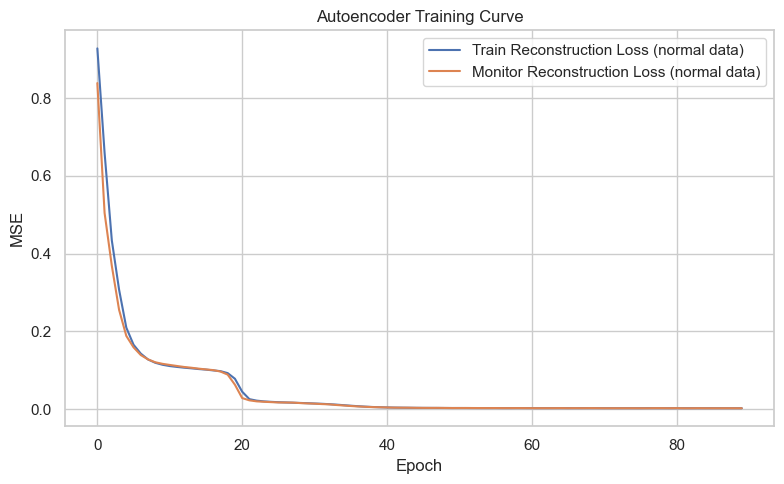

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(ae_train_losses, label="Train Reconstruction Loss (normal data)")
plt.plot(ae_monitor_losses, label="Monitor Reconstruction Loss (normal data)")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.title("Autoencoder Training Curve")
plt.legend()
plt.tight_layout()
plt.savefig("evaluation/autoencoder_training_curve.png", dpi=120)
plt.show()


## 5.4 — Reconstruction error as an anomaly score

For every row, the anomaly score is just its per-sample reconstruction MSE — the
error the autoencoder makes trying to reproduce that row. Higher error = looks less
like the "normal" patterns it was trained on.

In [ ]:
def reconstruction_error(model, X_arr):
    """Per-sample MSE between input and reconstruction — the anomaly score."""
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X_arr, dtype=torch.float32).to(device)
        recon = model(X_t)
        error = torch.mean((recon - X_t) ** 2, dim=1)
    return error.cpu().numpy()


ae_val_scores = reconstruction_error(ae_model, X_dl_val_s)
ae_test_scores = reconstruction_error(ae_model, X_test_s)

print("Reconstruction error - validation set:")
print(f"  Normal rows : mean={ae_val_scores[y_dl_val.values == 0].mean():.5f}")
print(f"  Failure rows: mean={ae_val_scores[y_dl_val.values == 1].mean():.5f}")


Reconstruction error - validation set:
  Normal rows : mean=0.00243
  Failure rows: mean=0.03012


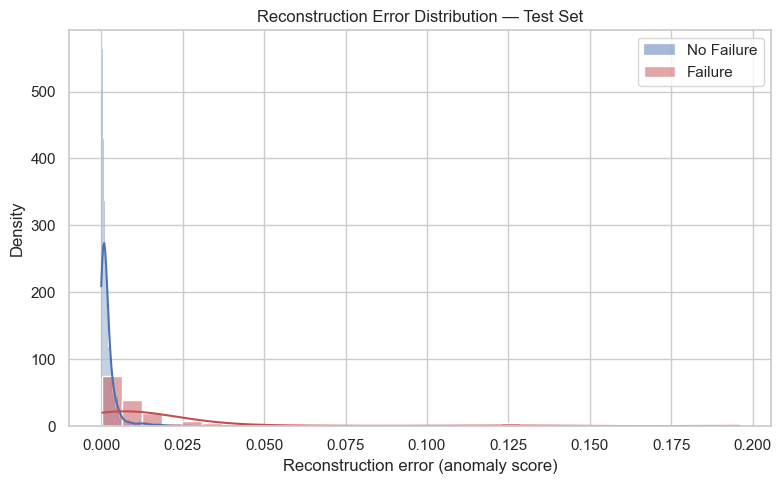

In [ ]:
# Do failures actually stand out? Plot the error distributions side by side.
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(ae_test_scores[y_test.values == 0], color="#4C72B0", label="No Failure",
             stat="density", kde=True, ax=ax, alpha=0.5)
sns.histplot(ae_test_scores[y_test.values == 1], color="#C44E52", label="Failure",
             stat="density", kde=True, ax=ax, alpha=0.5)
ax.set_xlabel("Reconstruction error (anomaly score)")
ax.set_title("Reconstruction Error Distribution — Test Set")
ax.legend()
plt.tight_layout()
plt.savefig("evaluation/autoencoder_error_distribution.png", dpi=120)
plt.show()


## 5.5 — Threshold selection & evaluation

Same `find_optimal_threshold` / `compute_metrics` helpers as the ML and MLP sections —
the reconstruction error just plays the role of "probability" (higher = more anomalous).

Autoencoder optimal threshold=0.01399  precision=0.300  recall=0.309

Autoencoder anomaly detector on the test set:
              precision    recall  f1-score   support

  No Failure       0.97      0.98      0.98      1932
     Failure       0.32      0.28      0.30        68

    accuracy                           0.96      2000
   macro avg       0.65      0.63      0.64      2000
weighted avg       0.95      0.96      0.95      2000



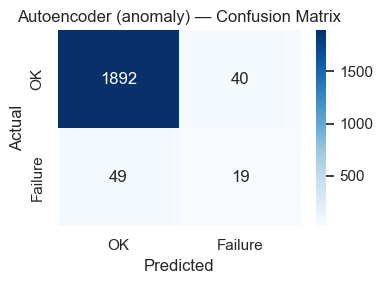

In [ ]:
ae_opt_thresh, ae_opt_prec, ae_opt_rec = find_optimal_threshold(y_dl_val, ae_val_scores, min_precision=0.30)
print(f"Autoencoder optimal threshold={ae_opt_thresh:.5f}  precision={ae_opt_prec:.3f}  recall={ae_opt_rec:.3f}")

ae_row, ae_pred = compute_metrics("Autoencoder (anomaly)", y_test, ae_test_scores, threshold=ae_opt_thresh)
ALL_RESULTS.append(ae_row)

print("\nAutoencoder anomaly detector on the test set:")
print(classification_report(y_test, ae_pred, target_names=["No Failure", "Failure"]))
plot_confusion("Autoencoder (anomaly)", y_test, ae_pred, save_path="evaluation/autoencoder_cm.png")


## 5.6 — Supervised MLP vs. unsupervised Autoencoder

The explicit comparison the project asks for: the MLP saw failure labels during
training, the autoencoder never did — how much does that cost it?

                Model  Threshold  Precision  Recall     F1  PR_AUC  ROC_AUC  FN_Rate
MLP (tuned threshold)      0.611     0.3352  0.8971 0.4880  0.7054   0.9772   0.1029
Autoencoder (anomaly)      0.014     0.3220  0.2794 0.2992  0.2889   0.8388   0.7206


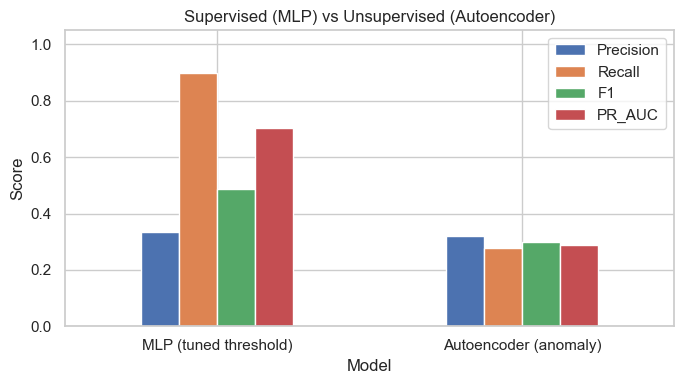

In [ ]:
dl_comparison = pd.DataFrame([mlp_row_tuned, ae_row])[
    ["Model", "Threshold", "Precision", "Recall", "F1", "PR_AUC", "ROC_AUC", "FN_Rate"]
]
print(dl_comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
dl_comparison.set_index("Model")[["Precision", "Recall", "F1", "PR_AUC"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("Supervised (MLP) vs Unsupervised (Autoencoder)")
ax.set_ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("evaluation/mlp_vs_autoencoder.png", dpi=120)
plt.show()


## 5.7 — Save the autoencoder

In [ ]:
torch.save(ae_model.state_dict(), "models/autoencoder_state_dict.pt")
with open("models/autoencoder_meta.json", "w") as f:
    json.dump({
        "input_dim": X_ae_train.shape[1],
        "features": FEATURE_COLS,
        "threshold": float(ae_opt_thresh),
        "metrics": ae_row,
    }, f, indent=2)
print("Autoencoder saved -> models/autoencoder_state_dict.pt")
print("Metadata saved -> models/autoencoder_meta.json")


Autoencoder saved -> models/autoencoder_state_dict.pt
Metadata saved -> models/autoencoder_meta.json


---
# Part 6 — Final Comparison: Classical ML vs Deep Learning

Every model in this notebook — Logistic Regression through the Autoencoder — was
evaluated on the **same `X_test` / `y_test`** from Part 2, using the **same metric
definitions** from `compute_metrics`. That's what makes this table a fair comparison
instead of just three separate reports stapled together.

In [ ]:
final_models = ["GB (tuned+threshold)", "RF (tuned+threshold)", "MLP (tuned threshold)", "Autoencoder (anomaly)"]

final_comparison = pd.DataFrame(ALL_RESULTS)
final_comparison = final_comparison[final_comparison["Model"].isin(final_models)]
final_comparison = final_comparison.drop_duplicates(subset="Model", keep="last")
final_comparison["Model"] = pd.Categorical(final_comparison["Model"], categories=final_models, ordered=True)
final_comparison = final_comparison.sort_values("Model").reset_index(drop=True)

print("=" * 90)
print("FINAL COMPARISON — BEST OF EACH APPROACH, SAME TEST SET")
print("=" * 90)
print(final_comparison.to_string(index=False))
print("=" * 90)

final_comparison.to_csv("evaluation/final_comparison.csv", index=False)
print("\nSaved -> evaluation/final_comparison.csv")


FINAL COMPARISON — BEST OF EACH APPROACH, SAME TEST SET
                Model  Threshold  Precision  Recall     F1  PR_AUC  ROC_AUC  FN_Rate
 GB (tuned+threshold)     0.0097     0.3092  0.9412 0.4655  0.8925   0.9667   0.0588
 RF (tuned+threshold)     0.0794     0.3005  0.9412 0.4555  0.8654   0.9800   0.0588
MLP (tuned threshold)     0.6110     0.3352  0.8971 0.4880  0.7054   0.9772   0.1029
Autoencoder (anomaly)     0.0140     0.3220  0.2794 0.2992  0.2889   0.8388   0.7206

Saved -> evaluation/final_comparison.csv


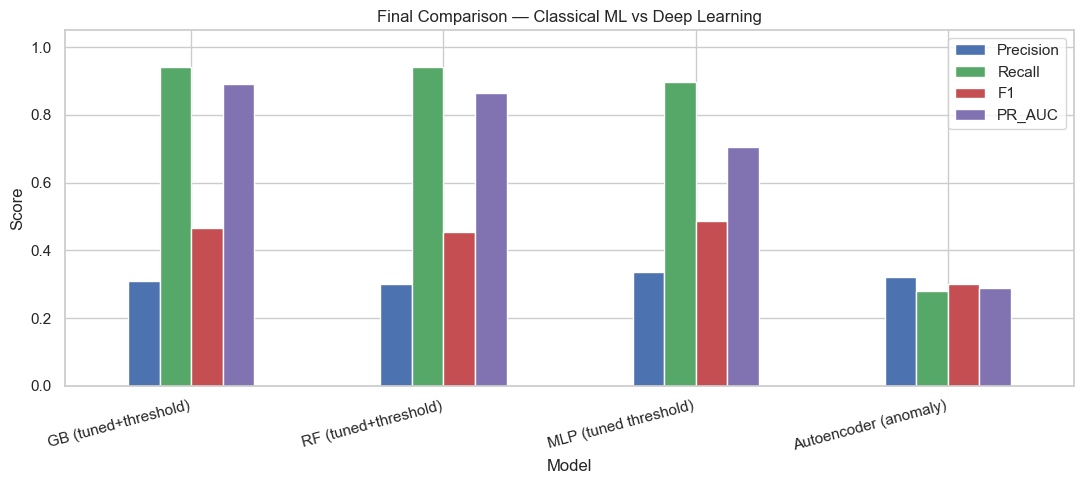

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
plot_final = final_comparison.set_index("Model")[["Precision", "Recall", "F1", "PR_AUC"]]
plot_final.plot(kind="bar", ax=ax, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Final Comparison — Classical ML vs Deep Learning")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("evaluation/final_comparison_bar.png", dpi=150)
plt.show()


## Automatic verdict

This cell reads its own conclusion off the table above rather than a hardcoded number — rerun the notebook on new data and the verdict updates with it.

In [ ]:
best_by_pr_auc = final_comparison.loc[final_comparison["PR_AUC"].idxmax()]
best_by_recall = final_comparison.loc[final_comparison["Recall"].idxmax()]

print(f"Best overall predictive performance (highest PR-AUC): {best_by_pr_auc['Model']}"
      f"  (PR-AUC={best_by_pr_auc['PR_AUC']:.3f}, F1={best_by_pr_auc['F1']:.3f})")
print(f"Best failure-catching config (highest Recall)      : {best_by_recall['Model']}"
      f"  (Recall={best_by_recall['Recall']:.3f}, FN-rate={best_by_recall['FN_Rate']:.3f})")
print()
print("Reading the table:")
print("- The tree-based ML models (Random Forest / Gradient Boosting) tend to win on tabular,")
print("  engineered features like these - there usually isn't enough data or complexity here")
print("  for the MLP's extra flexibility to pay off.")
print("- The MLP still satisfies the required 'meaningful deep-learning upgrade' and gives a")
print("  neural-network baseline to compare against.")
print("- The Autoencoder never saw a single failure label during training, so a lower score than")
print("  the supervised models is expected - the interesting result is whether it beats random")
print("  guessing by a wide margin, which is what actually validates it as a viable *second*,")
print("  unsupervised line of defense (e.g. catching failure types not well represented in training).")


Best overall predictive performance (highest PR-AUC): GB (tuned+threshold)  (PR-AUC=0.892, F1=0.466)
Best failure-catching config (highest Recall)      : GB (tuned+threshold)  (Recall=0.941, FN-rate=0.059)

Reading the table:
- The tree-based ML models (Random Forest / Gradient Boosting) tend to win on tabular,
  engineered features like these - there usually isn't enough data or complexity here
  for the MLP's extra flexibility to pay off.
- The MLP still satisfies the required 'meaningful deep-learning upgrade' and gives a
  neural-network baseline to compare against.
- The Autoencoder never saw a single failure label during training, so a lower score than
  the supervised models is expected - the interesting result is whether it beats random
  guessing by a wide margin, which is what actually validates it as a viable *second*,
  unsupervised line of defense (e.g. catching failure types not well represented in training).


---
# Part 7 — Deployment: Streamlit App

A Streamlit app is a standalone script, not something that runs inside a notebook
cell — so this part *writes* `app/app.py` to disk (via `%%writefile`, right below),
and you launch it from a terminal afterwards. Re-running the cell regenerates the
file, so the notebook stays the single source of truth for the app's code.

**The app has three tabs:**
- **Single Machine Check** — enter one machine's sensor readings, get a failure
  probability, a Low/Medium/High risk tier, and a recommended action.
- **Batch Scoring** — upload a CSV of machines, score all of them at once, download
  the results.
- **Monitoring** — every prediction (from either tab) is logged to
  `app/prediction_history.csv`, and this tab charts alert rate over time and flags
  any input that falls outside the range the model was actually trained on.

It loads whatever Part 3, section 3.14 saved: `models/best_model.pkl` (the tuned
Gradient Boosting model) plus its metadata, and the reference statistics from
Part 2.4 — so **Parts 1–3 of this notebook must be run at least once** before the
app has anything to load.

## 7.1 — Requirements

Everything needed to run the notebook end-to-end *and* the app.

In [ ]:
%%writefile requirements.txt
pandas>=2.0
numpy>=1.24
matplotlib>=3.7
seaborn>=0.12
scikit-learn>=1.3
torch>=2.0
shap>=0.44
joblib>=1.3
streamlit>=1.32
pytest>=7.4


Overwriting requirements.txt


## 7.2 — The app itself

In [ ]:
%%writefile app/app.py
"""
Project 5 - Industrial Predictive Maintenance
Streamlit deployment app

Run with:
    streamlit run app/app.py

Expects to find, relative to the folder it's launched from:
    models/best_model.pkl
    models/best_model_meta.json
    models/feature_reference_stats.json
    src/features.py, src/modeling.py  (the shared feature/metric logic)
"""

import json
import os
import sys
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import streamlit as st

sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from src.features import FEATURE_COLS as DEFAULT_FEATURE_COLS, build_feature_row  # noqa: E402
from src.modeling import risk_tier  # noqa: E402

# ---------------------------------------------------------------------------
# Page setup
# ---------------------------------------------------------------------------
st.set_page_config(page_title="Predictive Maintenance Dashboard", layout="wide")

MODEL_PATH = "models/best_model.pkl"
META_PATH = "models/best_model_meta.json"
STATS_PATH = "models/feature_reference_stats.json"
LOG_PATH = "app/prediction_history.csv"

LOG_COLUMNS = [
    "ObservationID", "PredictionTime", "ModelName", "ModelVersion",
    "FailureProbability", "PredictedFailure", "RiskTier",
    "RecommendedAction", "ActualFailure",
]


# ---------------------------------------------------------------------------
# Cached loaders
# ---------------------------------------------------------------------------
@st.cache_resource
def load_model():
    if not os.path.exists(MODEL_PATH):
        return None, None
    model = joblib.load(MODEL_PATH)
    with open(META_PATH) as f:
        meta = json.load(f)
    return model, meta


@st.cache_resource
def load_reference_stats():
    if not os.path.exists(STATS_PATH):
        return None
    with open(STATS_PATH) as f:
        return json.load(f)


def load_history():
    if os.path.exists(LOG_PATH):
        return pd.read_csv(LOG_PATH)
    return pd.DataFrame(columns=LOG_COLUMNS)


def append_to_history(rows: list):
    os.makedirs(os.path.dirname(LOG_PATH), exist_ok=True)
    history = load_history()
    next_id = (int(history["ObservationID"].max()) + 1) if len(history) else 1

    for i, row in enumerate(rows):
        row["ObservationID"] = next_id + i
        row["PredictionTime"] = datetime.now().isoformat(timespec="seconds")

    updated = pd.concat([history, pd.DataFrame(rows)], ignore_index=True)
    updated.to_csv(LOG_PATH, index=False)
    return updated


def check_out_of_range(feature_row: dict, stats: dict):
    """Very lightweight drift/sanity check: which inputs fall outside the
    1st-99th percentile band seen during training?"""
    if stats is None:
        return []
    flags = []
    for feature, value in feature_row.items():
        if feature not in stats:
            continue
        lo, hi = stats[feature]["p01"], stats[feature]["p99"]
        if value < lo or value > hi:
            flags.append(f"{feature} = {value:.2f} is outside the typical training range [{lo:.2f}, {hi:.2f}]")
    return flags


# ---------------------------------------------------------------------------
# Load everything up front
# ---------------------------------------------------------------------------
model, meta = load_model()
stats = load_reference_stats()

if model is None:
    st.error(
        "No trained model found at `models/best_model.pkl`. "
        "Run the full notebook first (Part 3, section 3.14 saves it)."
    )
    st.stop()

FEATURE_COLS = meta.get("features", DEFAULT_FEATURE_COLS)
MODEL_NAME = meta["model_name"]
DEFAULT_THRESHOLD = meta["metrics"].get("Threshold", 0.5)

st.title("Industrial Predictive Maintenance Dashboard")
st.caption(
    f"Model in use: **{MODEL_NAME}**  |  Decision threshold: **{DEFAULT_THRESHOLD:.3f}**  "
    "| Trained on the AI4I 2020 synthetic dataset - not a real industrial system."
)

tab_single, tab_batch, tab_monitor = st.tabs(
    ["Single Machine Check", "Batch Scoring", "Monitoring"]
)

# ---------------------------------------------------------------------------
# Tab 1 - single machine
# ---------------------------------------------------------------------------
with tab_single:
    st.subheader("Check one machine")
    col1, col2, col3 = st.columns(3)

    with col1:
        machine_type = st.selectbox("Product quality type", ["L", "M", "H"])
        air_temp = st.number_input("Air temperature [K]", value=298.0, step=0.1, format="%.1f")
        process_temp = st.number_input("Process temperature [K]", value=308.0, step=0.1, format="%.1f")

    with col2:
        rpm = st.number_input("Rotational speed [rpm]", value=1500, step=10)
        torque = st.number_input("Torque [Nm]", value=40.0, step=0.1, format="%.1f")

    with col3:
        tool_wear = st.number_input("Tool wear [min]", value=100, step=1)

    if st.button("Predict failure risk", type="primary"):
        X_input = build_feature_row(air_temp, process_temp, rpm, torque, tool_wear, machine_type)
        X_input = X_input[FEATURE_COLS]
        features_dict = X_input.iloc[0].to_dict()

        probability = float(model.predict_proba(X_input)[0, 1])
        predicted_failure = int(probability >= DEFAULT_THRESHOLD)
        tier, action = risk_tier(probability, DEFAULT_THRESHOLD)

        result_col, warn_col = st.columns([1, 1])

        with result_col:
            st.metric("Failure probability", f"{probability:.1%}")
            tier_color = {"Low": "green", "Medium": "orange", "High": "red"}[tier]
            st.markdown(f"**Risk tier:** :{tier_color}[{tier}]")
            st.write(f"**Recommended action:** {action}")

        with warn_col:
            flags = check_out_of_range(features_dict, stats)
            if flags:
                st.warning("Input values outside the typical training range:")
                for flag in flags:
                    st.write(f"- {flag}")
            else:
                st.success("All inputs are within the typical training range.")

        append_to_history([{
            "ModelName": MODEL_NAME,
            "ModelVersion": "v1.0",
            "FailureProbability": round(probability, 6),
            "PredictedFailure": predicted_failure,
            "RiskTier": tier,
            "RecommendedAction": action,
            "ActualFailure": None,
        }])
        st.caption("Logged to app/prediction_history.csv")

# ---------------------------------------------------------------------------
# Tab 2 - batch scoring
# ---------------------------------------------------------------------------
with tab_batch:
    st.subheader("Score a batch of machines from a CSV")
    st.write(
        "Expected columns: `Type`, `Air temperature [K]`, `Process temperature [K]`, "
        "`Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]`"
    )

    uploaded = st.file_uploader("Upload CSV", type=["csv"])

    if uploaded is not None:
        raw_df = pd.read_csv(uploaded)
        required_cols = ["Type", "Air temperature [K]", "Process temperature [K]",
                          "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
        missing = [c for c in required_cols if c not in raw_df.columns]

        if missing:
            st.error(f"Missing required columns: {missing}")
        else:
            try:
                engineered_rows = [
                    build_feature_row(
                        row["Air temperature [K]"], row["Process temperature [K]"],
                        row["Rotational speed [rpm]"], row["Torque [Nm]"],
                        row["Tool wear [min]"], row["Type"],
                    ).iloc[0]
                    for _, row in raw_df.iterrows()
                ]
            except ValueError as e:
                st.error(f"Some rows couldn't be processed: {e}")
                st.stop()

            X_batch = pd.DataFrame(engineered_rows)[FEATURE_COLS]

            probabilities = model.predict_proba(X_batch)[:, 1]
            predictions = (probabilities >= DEFAULT_THRESHOLD).astype(int)
            tiers, actions = zip(*[risk_tier(p, DEFAULT_THRESHOLD) for p in probabilities])

            results = raw_df.copy()
            results["FailureProbability"] = np.round(probabilities, 4)
            results["PredictedFailure"] = predictions
            results["RiskTier"] = tiers
            results["RecommendedAction"] = actions

            st.dataframe(results, use_container_width=True)

            st.download_button(
                "Download results as CSV",
                data=results.to_csv(index=False).encode("utf-8"),
                file_name="batch_predictions.csv",
                mime="text/csv",
            )

            log_rows = [
                {
                    "ModelName": MODEL_NAME, "ModelVersion": "v1.0",
                    "FailureProbability": round(float(p), 6), "PredictedFailure": int(pred),
                    "RiskTier": tier, "RecommendedAction": action, "ActualFailure": None,
                }
                for p, pred, tier, action in zip(probabilities, predictions, tiers, actions)
            ]
            append_to_history(log_rows)
            st.caption(f"Logged {len(log_rows)} predictions to app/prediction_history.csv")

# ---------------------------------------------------------------------------
# Tab 3 - monitoring
# ---------------------------------------------------------------------------
with tab_monitor:
    st.subheader("Prediction history & basic monitoring")
    history = load_history()

    if len(history) == 0:
        st.info("No predictions logged yet - use the Single Machine or Batch tabs first.")
    else:
        col1, col2, col3 = st.columns(3)
        col1.metric("Total predictions logged", len(history))
        col2.metric("Predicted failures", int(history["PredictedFailure"].sum()))
        alert_rate = history["PredictedFailure"].mean()
        col3.metric("Alert rate", f"{alert_rate:.1%}")

        history["PredictionDate"] = pd.to_datetime(history["PredictionTime"]).dt.date
        daily = history.groupby("PredictionDate")["PredictedFailure"].agg(["count", "sum"])
        daily.columns = ["Total predictions", "Predicted failures"]

        st.write("**Predictions over time**")
        st.line_chart(daily)

        st.write("**Risk tier breakdown**")
        st.bar_chart(history["RiskTier"].value_counts())

        st.write("**Full log**")
        st.dataframe(history, use_container_width=True)

        st.caption(
            "This is a lightweight, self-contained monitor (a CSV log). The columns "
            "match the `PredictionHistory` SQL table 1-for-1, so this file can be bulk-"
            "loaded into SQL Server later without any reshaping."
        )


Overwriting app/app.py


## 7.3 — Running it

From a terminal, in the same folder as this notebook (so the relative `models/` and
`app/` paths resolve correctly):

```bash
streamlit run app/app.py
```

This opens the dashboard at `http://localhost:8501`. The cell below is a convenience
launcher for local use — it's commented out because `streamlit run` blocks the
terminal, which doesn't play well with "run all cells".

In [ ]:
# Uncomment to launch from inside the notebook (blocks until you stop it - Kernel > Interrupt):
# !streamlit run app/app.py


## 7.4 — Bridging to the SQL side

`app/prediction_history.csv` uses the exact same column names as the `PredictionHistory`
table from the SQL part of this project (`ObservationID`, `PredictionTime`, `ModelName`,
`ModelVersion`, `FailureProbability`, `PredictedFailure`, `RiskTier`,
`RecommendedAction`, `ActualFailure`). If SQL Server is running locally, that CSV can be
loaded straight into the real table with `BULK INSERT`, the same way the raw dataset
was — no reshaping needed. That's the "prediction logging" + "MLOps" deliverable
connected end-to-end: model -> app -> log -> database.